<a href="https://colab.research.google.com/github/EstibenMT/machine_learning/blob/main/Actividad_5y6_Entrega_Final_Segmentacion_Clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentación de clientes de un centro comercial

Taller de Aprendizaje No Supervisado: K-Means y clustering jerárquico

Estiben Montoya Taborda · Grupo 13

Uso el dataset Mall Customer Segmentation Data (`Mall_Customers.csv`) de la guía. Lo cargo desde una copia pública en GitHub.

## Parte 1. EDA, escalamiento y K-Means

El centro comercial quiere separar a sus clientes en grupos para tratarlos distinto. Como no hay una columna que diga a qué grupo pertenece cada uno, es un problema no supervisado.

### Configuración

Importo las librerías y fijo `SEMILLA = 212`. K-Means arranca con centroides al azar, así que sin semilla los grupos pueden salir numerados distinto en cada ejecución. Uso la misma semilla en todo el cuaderno.

In [1]:
# ==============================================================================
# CONFIGURACIÓN GENERAL Y LIBRERÍAS
# ==============================================================================

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

# Semilla única para todo el cuaderno (centroides iniciales de K-Means)
SEMILLA = 212

### **Paso 1. Análisis exploratorio de datos (EDA) y selección de variables**

#### **Inspección estructural**

Primero reviso cómo vienen los datos: tamaño, tipos, nulos y duplicados. Los duplicados los busco también sin `ID_Cliente`, porque con un ID distinto en cada fila nunca saldrían repetidos.

In [2]:
# ==============================================================================
# CARGA DEL CONJUNTO DE DATOS (Mall Customer Segmentation Data)
# ==============================================================================

# Se intenta primero la copia pública del archivo; si no hay conexión se usa el CSV local
DATA_URL = "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv"

try:
    mall_df = pd.read_csv(DATA_URL)
    print("• Datos cargados desde la URL pública")
except Exception:
    mall_df = pd.read_csv("Mall_Customers.csv")
    print("• Datos cargados desde el archivo local Mall_Customers.csv")

# Copia de trabajo para no alterar los datos originales
mall_prep_df = mall_df.copy()

# Renombramos las columnas al español para que tablas y gráficos queden consistentes
traduccion = {
    "CustomerID": "ID_Cliente",
    "Genre": "Genero",
    "Age": "Edad",
    "Annual Income (k$)": "Ingreso_Anual_kUSD",
    "Spending Score (1-100)": "Puntaje_Gasto",
}
mall_prep_df = mall_prep_df.rename(columns=traduccion)

# Inspección estructural
print("\n--- INSPECCIÓN ESTRUCTURAL ---")
print(f"• Dimensiones (filas, columnas): {mall_prep_df.shape}")
print(f"• Valores nulos totales:         {mall_prep_df.isna().sum().sum()}")
print(f"• Registros duplicados:          {mall_prep_df.duplicated().sum()}")
print(f"• Duplicados ignorando el ID:    {mall_prep_df.drop(columns='ID_Cliente').duplicated().sum()}")

print("\nTipos de variables:")
print(mall_prep_df.dtypes)

print("\nDistribución del género:")
print(mall_prep_df["Genero"].value_counts())
display(mall_prep_df.head())

• Datos cargados desde la URL pública

--- INSPECCIÓN ESTRUCTURAL ---
• Dimensiones (filas, columnas): (200, 5)
• Valores nulos totales:         0
• Registros duplicados:          0
• Duplicados ignorando el ID:    0

Tipos de variables:
ID_Cliente             int64
Genero                object
Edad                   int64
Ingreso_Anual_kUSD     int64
Puntaje_Gasto          int64
dtype: object

Distribución del género:
Genero
Female    112
Male       88
Name: count, dtype: int64


,ID_Cliente,Genero,Edad,Ingreso_Anual_kUSD,Puntaje_Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


La tabla tiene 200 filas y 5 columnas, sin nulos ni duplicados, así que no hay nada que limpiar. `ID_Cliente` solo numera a los clientes (1 a 200) y no los describe; si lo dejo, el algoritmo buscaría parecidos entre números sin sentido, por eso lo saco. `Genero` es la única categórica (112 mujeres y 88 hombres).

#### **Análisis estadístico y visual**

Para tener una visión general de los datos, mi intención es analizar la tendencia central y la dispersión de las variables numéricas. Después, elaboro gráficos: histogramas y diagramas de caja para examinar cada variable por separado, y diagramas de dispersión y una matriz de correlación para observar cómo se relacionan entre sí.

In [3]:
# ==============================================================================
# ESTADÍSTICOS DESCRIPTIVOS DE LAS VARIABLES NUMÉRICAS
# ==============================================================================

cols_numericas = ["Edad", "Ingreso_Anual_kUSD", "Puntaje_Gasto"]

# Tendencia central y dispersión, más rango intercuartílico y asimetría
stats_desc = mall_prep_df[cols_numericas].describe().T
stats_desc["IQR"] = stats_desc["75%"] - stats_desc["25%"]
stats_desc["Asimetría"] = mall_prep_df[cols_numericas].skew()
stats_desc = stats_desc[["mean", "std", "min", "25%", "50%", "75%", "max", "IQR", "Asimetría"]]
stats_desc.columns = ["Media", "Desv.Est.", "Mín.", "Q1", "Mediana", "Q3", "Máx.", "IQR", "Asimetría"]

print("--- ESTADÍSTICOS DESCRIPTIVOS ---")
display(stats_desc.round(2))

--- ESTADÍSTICOS DESCRIPTIVOS ---


,Media,Desv.Est.,Mín.,Q1,Mediana,Q3,Máx.,IQR,Asimetría
Edad,38.85,13.97,18.0,28.75,36.0,49.0,70.0,20.25,0.49
Ingreso_Anual_kUSD,60.56,26.26,15.0,41.50,61.5,78.0,137.0,36.50,0.32
Puntaje_Gasto,50.20,25.82,1.0,34.75,50.0,73.0,99.0,38.25,-0.05


Las estadísticas descriptivas muestran que la **edad** va de 18 a 70 años, con una media de 38.85 y una mediana de 36. El **ingreso anual** va de 15 a 137 mil dólares, con una media de 60.56 y una mediana de 61.5. Por su parte, el **puntaje de gasto** va de 1 a 99, con una media de 50.2 y una mediana de 50. En las tres variables la media y la mediana son cercanas, lo que indica distribuciones sin un sesgo marcado. Además, las desviaciones estándar del ingreso (26.26) y del puntaje de gasto (25.82) son casi iguales, un hallazgo que retomaré en el paso de escalamiento.

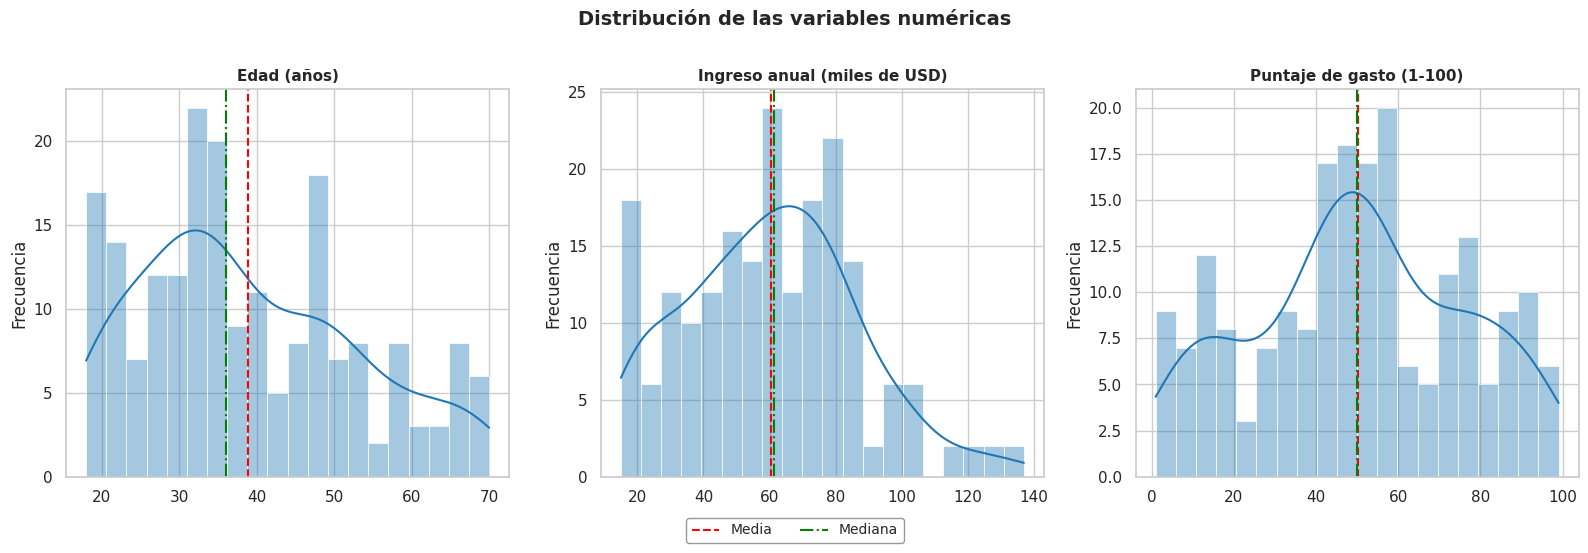

In [4]:
# ==============================================================================
# ANÁLISIS UNIVARIADO: DISTRIBUCIONES (HISTOGRAMA + KDE)
# ==============================================================================

etiquetas_ejes = {
    "Edad": "Edad (años)",
    "Ingreso_Anual_kUSD": "Ingreso anual (miles de USD)",
    "Puntaje_Gasto": "Puntaje de gasto (1-100)",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(cols_numericas):
    datos_col = mall_prep_df[col].dropna()
    sns.histplot(datos_col, kde=True, ax=axes[i], color="#1f77b4", alpha=0.4,
                 bins=20, edgecolor="white", linewidth=0.5)
    linea_media = axes[i].axvline(datos_col.mean(), color="red", linestyle="--", linewidth=1.5, label="Media")
    linea_mediana = axes[i].axvline(datos_col.median(), color="green", linestyle="-.", linewidth=1.5, label="Mediana")
    axes[i].set_title(etiquetas_ejes[col], fontweight="bold", fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia")

fig.legend(handles=[linea_media, linea_mediana], labels=["Media", "Mediana"], loc="lower center",
           bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=10, frameon=True, facecolor="white", edgecolor="gray")
plt.suptitle("Distribución de las variables numéricas", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Los histogramas no tienen una forma de campana bien definida. La edad se concentra entre los 30 y los 35 años y presenta una cola hacia la derecha que llega hasta los 70. El ingreso tiene picos cerca de los 60 y los 78 mil dólares, y el puntaje de gasto muestra zonas altas cerca de 15 y de 80. La presencia de varios picos me lleva a pensar que hay subgrupos mezclados en los datos, que es justo lo que K-Means debería separar.

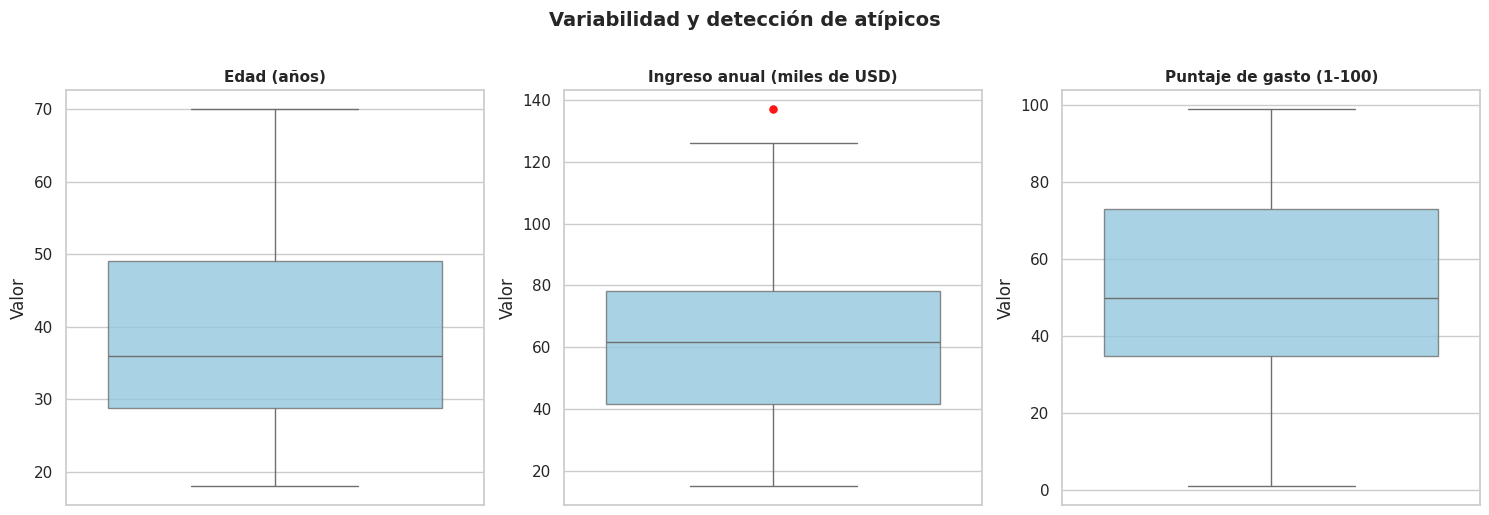

--- ATÍPICOS SEGÚN LA REGLA DEL IQR (1.5 x IQR) ---
• Edad: 0 atípicos (límites de -1.6 a 79.4)
• Ingreso_Anual_kUSD: 2 atípicos (límites de -13.2 a 132.8)
• Puntaje_Gasto: 0 atípicos (límites de -22.6 a 130.4)

Clientes con ingreso atípico:


,ID_Cliente,Genero,Edad,Ingreso_Anual_kUSD,Puntaje_Gasto
198,199,Male,32,137,18
199,200,Male,30,137,83


In [5]:
# ==============================================================================
# DETECCIÓN DE ATÍPICOS: DIAGRAMAS DE CAJA Y REGLA DEL IQR
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(cols_numericas):
    sns.boxplot(y=mall_prep_df[col], ax=axes[i], color="#87CEEB",
                flierprops=dict(marker="o", markerfacecolor="red", markeredgecolor="none", markersize=6, alpha=0.7),
                boxprops=dict(alpha=0.8))
    axes[i].set_title(etiquetas_ejes[col], fontweight="bold", fontsize=11)
    axes[i].set_ylabel("Valor")

plt.suptitle("Variabilidad y detección de atípicos", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Conteo de atípicos con la regla de 1.5 veces el rango intercuartílico
print("--- ATÍPICOS SEGÚN LA REGLA DEL IQR (1.5 x IQR) ---")
for col in cols_numericas:
    q1, q3 = mall_prep_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = mall_prep_df[(mall_prep_df[col] < limite_inf) | (mall_prep_df[col] > limite_sup)]
    print(f"• {col}: {len(atipicos)} atípicos (límites de {limite_inf:.1f} a {limite_sup:.1f})")

# Detalle de los atípicos del ingreso (la única variable que los presenta)
q1, q3 = mall_prep_df["Ingreso_Anual_kUSD"].quantile([0.25, 0.75])
limite_sup_ingreso = q3 + 1.5 * (q3 - q1)
print("\nClientes con ingreso atípico:")
display(mall_prep_df[mall_prep_df["Ingreso_Anual_kUSD"] > limite_sup_ingreso])

Al aplicar la regla del rango intercuartílico (IQR), solo el **ingreso anual** presenta valores atípicos: dos clientes hombres con 137 mil dólares. Decido conservarlos por dos razones. Primero, parecen ingresos altos reales y no un error de captura. Segundo, con solo 200 registros no quiero perder la parte alta de la distribución. Sin embargo, debo tener en cuenta que los centroides de K-Means son promedios y, por lo tanto, un valor extremo puede desplazarlos.

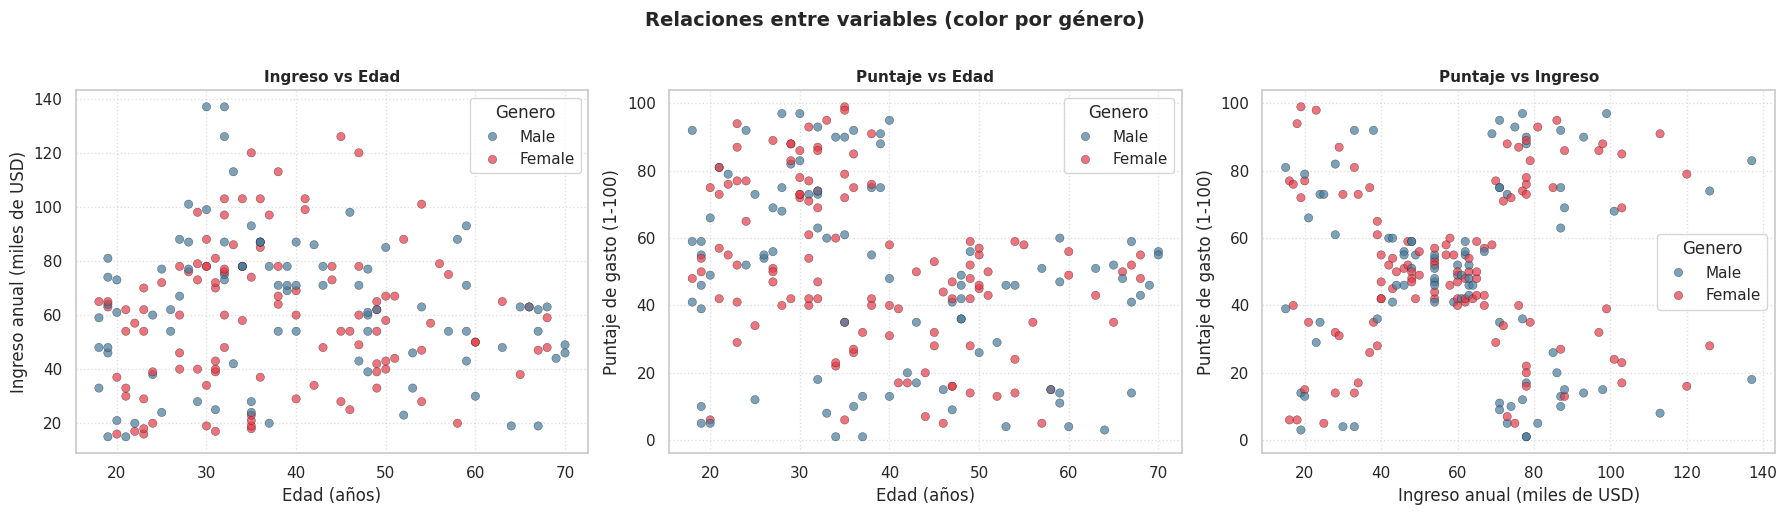

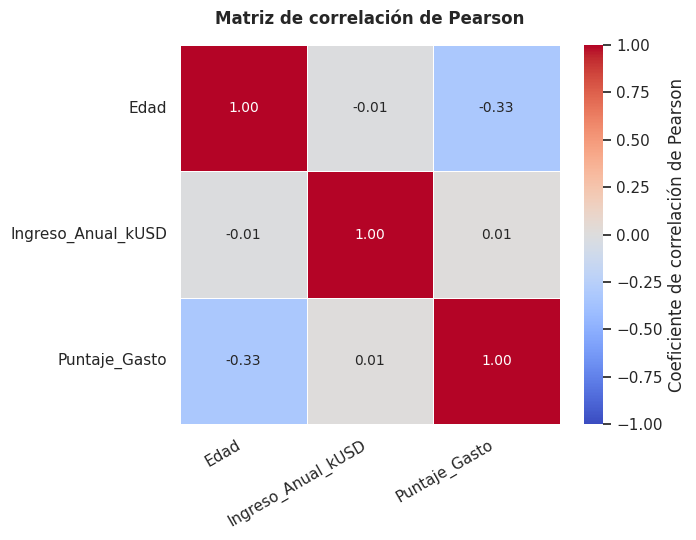

--- PROMEDIOS POR GÉNERO ---


,Edad,Ingreso_Anual_kUSD,Puntaje_Gasto
Genero,,,
Female,38.10,59.25,51.53
Male,39.81,62.23,48.51


In [6]:
# ==============================================================================
# ANÁLISIS BIVARIADO: DIAGRAMAS DE DISPERSIÓN Y MATRIZ DE CORRELACIÓN
# ==============================================================================

pares = [("Edad", "Ingreso_Anual_kUSD"), ("Edad", "Puntaje_Gasto"), ("Ingreso_Anual_kUSD", "Puntaje_Gasto")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (var_x, var_y) in zip(axes, pares):
    sns.scatterplot(data=mall_prep_df, x=var_x, y=var_y, hue="Genero",
                    palette={"Female": "#E63946", "Male": "#457B9D"},
                    alpha=0.7, edgecolor="k", linewidth=0.3, ax=ax)
    ax.set_xlabel(etiquetas_ejes[var_x])
    ax.set_ylabel(etiquetas_ejes[var_y])
    ax.set_title(f"{var_y.split('_')[0]} vs {var_x.split('_')[0]}", fontweight="bold", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.suptitle("Relaciones entre variables (color por género)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Matriz de correlación de Pearson
matriz_correlacion = mall_prep_df[cols_numericas].corr(method="pearson")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Coeficiente de correlación de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación de Pearson", fontsize=12, fontweight="bold", pad=15)
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Diferencias promedio por género
print("--- PROMEDIOS POR GÉNERO ---")
display(mall_prep_df.groupby("Genero")[cols_numericas].mean().round(2))

El **ingreso anual** y el **puntaje de gasto** casi no se relacionan (correlación de 0.01), lo que indica que ganar más no implica gastar más. La **edad**, en cambio, muestra una relación negativa moderada con el puntaje de gasto (-0.33): a mayor edad, tiende a ser menor el puntaje. Para agrupar, me conviene que el ingreso y el puntaje no sean redundantes, porque cada uno aporta información distinta.

En los diagramas de dispersión, el ingreso frente al puntaje forma concentraciones separadas y no una nube uniforme, una estructura favorable para un algoritmo de agrupamiento. El **género**, en cambio, no permite distinguir grupos: las mujeres promedian 51.5 de puntaje y los hombres 48.5, una diferencia pequeña.

#### **Selección de características**

Las características que utilizaré son el **ingreso anual** y el **puntaje de gasto**, por tres razones: describen directamente la relación del cliente con el centro comercial, prácticamente no están correlacionadas (0.01) y forman agrupaciones visibles al graficarlas. `ID_Cliente` queda fuera. `Edad` y `Genero` no participan en el cálculo de distancias, pero los uso después para describir los grupos obtenidos. Para verificar esta decisión, repito en el paso 3 la búsqueda del número de grupos (*k*) incluyendo la edad.

### **Paso 2. Escalamiento y preparación de los datos**

#### **Transformación de escala**

Antes de entrenar, realizo el escalamiento porque K-Means usa la distancia euclidiana y la variable con valores más grandes tendría más peso en el cálculo. Utilizo la estandarización (restar la media y dividir por la desviación estándar) y no el método min-max, porque este depende del mínimo y del máximo, y en este caso el máximo del ingreso lo determinan solo dos clientes. Con la estandarización, ambas variables quedan con media 0 y desviación estándar 1.

In [7]:
# ==============================================================================
# SELECCIÓN DE CARACTERÍSTICAS Y ESCALADO (StandardScaler)
# ==============================================================================

features_clustering = ["Ingreso_Anual_kUSD", "Puntaje_Gasto"]
X_cluster = mall_prep_df[features_clustering].copy()

print("--- RESUMEN DE LA PREPARACIÓN DE DATOS ---")
print(f"• Total de registros procesados: {X_cluster.shape[0]}")
print(f"• Variables seleccionadas para K-Means: {features_clustering}")
print(f"• Valores nulos restantes: {X_cluster.isna().sum().sum()}")

# Instanciamos el escalador
escalador = StandardScaler()

# Ajustamos y transformamos las variables de clustering
X_scaled = escalador.fit_transform(X_cluster)

# Convertimos a DataFrame para inspeccionar visualmente el resultado
X_scaled_df = pd.DataFrame(X_scaled, columns=features_clustering)

print("\n--- INSPECCIÓN DE DATOS ESCALADOS ---")
print("Promedios (deben ser cercanos a 0):\n", X_scaled_df.mean().round(2))
print("\nDesviaciones estándar (deben ser cercanas a 1):\n", X_scaled_df.std(ddof=0).round(2))
print("\nPrimeros 5 registros transformados:\n", X_scaled_df.head().round(3))

--- RESUMEN DE LA PREPARACIÓN DE DATOS ---
• Total de registros procesados: 200
• Variables seleccionadas para K-Means: ['Ingreso_Anual_kUSD', 'Puntaje_Gasto']
• Valores nulos restantes: 0

--- INSPECCIÓN DE DATOS ESCALADOS ---
Promedios (deben ser cercanos a 0):
 Ingreso_Anual_kUSD   -0.0
Puntaje_Gasto        -0.0
dtype: float64

Desviaciones estándar (deben ser cercanas a 1):
 Ingreso_Anual_kUSD    1.0
Puntaje_Gasto         1.0
dtype: float64

Primeros 5 registros transformados:
    Ingreso_Anual_kUSD  Puntaje_Gasto
0              -1.739         -0.435
1              -1.739          1.196
2              -1.701         -1.716
3              -1.701          1.040
4              -1.663         -0.396


#### Sustentación: qué pasaría sin escalar

Si dejo los datos en sus escalas originales, la variable con valores más grandes domina la distancia entre dos clientes. Los centroides son promedios de los clientes de cada grupo, así que también se ubican según esa variable y no según la estructura real de los datos.

En este conjunto de datos el escalamiento cambia poco, porque el ingreso (en miles de dólares) y el puntaje de gasto ya tienen desviaciones estándar parecidas. Para observar qué ocurre cuando las escalas sí son distintas, entreno tres modelos con *k* = 5 (el valor que justifico en el paso 3): uno sin escalar, otro con el ingreso expresado en dólares y otro con los datos estandarizados.

--- EFECTO DE LA ESCALA SOBRE K-MEANS (k = 5) ---


,ARI vs modelo C,Silueta (espacio escalado)
Modelo,,
A: sin escalar (ingreso en miles de USD),1.000,0.5547
B: sin escalar (ingreso en USD),0.427,0.1574
C: estandarizado,1.000,0.5547



Puntaje de gasto de los 5 centroides del modelo B (ingreso en USD):
[50.7 52.  49.6 49.7 50.1]


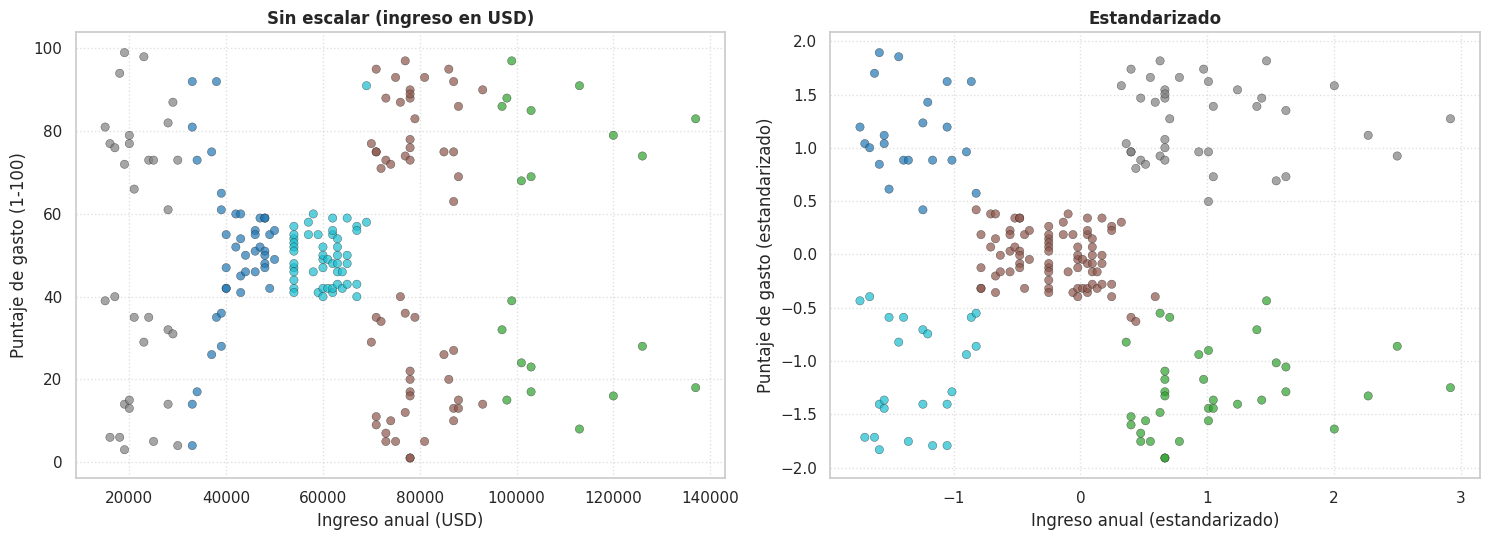

In [8]:
# ==============================================================================
# EXPERIMENTO: ¿QUÉ PASA SI NO SE ESCALAN LOS DATOS?
# ==============================================================================

# Modelo A: unidades originales (ingreso en miles de USD, puntaje de 1 a 100)
km_a = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10).fit(X_cluster)

# Modelo B: mismo ingreso pero expresado en USD, sin escalar
X_usd = X_cluster.copy()
X_usd["Ingreso_Anual_kUSD"] = X_usd["Ingreso_Anual_kUSD"] * 1000
km_b = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10).fit(X_usd)

# Modelo C: variables estandarizadas
km_c = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10).fit(X_scaled)

# Concordancia con el modelo estandarizado (ARI) y silueta medida en el espacio escalado
comparacion_escala = pd.DataFrame({
    "Modelo": ["A: sin escalar (ingreso en miles de USD)", "B: sin escalar (ingreso en USD)", "C: estandarizado"],
    "ARI vs modelo C": [adjusted_rand_score(km_a.labels_, km_c.labels_),
                        adjusted_rand_score(km_b.labels_, km_c.labels_), 1.0],
    "Silueta (espacio escalado)": [silhouette_score(X_scaled, km_a.labels_),
                                   silhouette_score(X_scaled, km_b.labels_),
                                   silhouette_score(X_scaled, km_c.labels_)],
}).set_index("Modelo")

print("--- EFECTO DE LA ESCALA SOBRE K-MEANS (k = 5) ---")
display(comparacion_escala.round(4))

# Puntaje de gasto promedio de cada centroide en el modelo B
print("\nPuntaje de gasto de los 5 centroides del modelo B (ingreso en USD):")
print(np.round(km_b.cluster_centers_[:, 1], 1))

# Visualización: modelo B contra modelo C
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(X_usd["Ingreso_Anual_kUSD"], X_usd["Puntaje_Gasto"], c=km_b.labels_, cmap="tab10",
                alpha=0.7, edgecolor="k", linewidth=0.3)
axes[0].set_title("Sin escalar (ingreso en USD)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Ingreso anual (USD)")
axes[0].set_ylabel("Puntaje de gasto (1-100)")

axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=km_c.labels_, cmap="tab10",
                alpha=0.7, edgecolor="k", linewidth=0.3)
axes[1].set_title("Estandarizado", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ingreso anual (estandarizado)")
axes[1].set_ylabel("Puntaje de gasto (estandarizado)")

for ax in axes:
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Comparo los tres modelos con el modelo C (estandarizado) usando el ARI, que vale 1 cuando dos particiones son idénticas. El modelo A (ingreso en miles de dólares, sin escalar) y el C producen exactamente la misma partición (ARI de 1.000 y silueta de 0.5547), porque el ingreso en miles y el puntaje de gasto ya tienen desviaciones estándar parecidas (26.26 y 25.82).

Con el ingreso en dólares (modelo B) el resultado cambia por completo. Su desviación estándar pasa a ser de unos 26,260, mil veces mayor que la del puntaje de gasto. Como la distancia euclidiana eleva las diferencias al cuadrado, el ingreso termina pesando alrededor de un millón de veces más y el puntaje de gasto prácticamente deja de influir. Por eso los cinco centroides quedan con un puntaje de gasto casi igual (entre 49.6 y 52), cercano a la media general (50.2), y el modelo se limita a cortar el eje del ingreso en franjas verticales, como se ve en el gráfico de la izquierda. La consecuencia es que clientes con ingresos parecidos pero hábitos de gasto opuestos (muy bajo y muy alto) quedan en el mismo grupo, y el bloque denso central se divide en dos franjas sin una razón real. Esta partición solo coincide parcialmente con la del modelo C (ARI de 0.43), y su silueta, medida en el espacio estandarizado, cae a 0.16 frente a 0.55.

En conclusión, sin escalar los centroides siguen a la variable de mayor magnitud. En este conjunto de datos no tuve problema únicamente porque las unidades ya eran parecidas; con otra unidad, el resultado habría dejado de ser útil. Continúo con los datos estandarizados.

### **Paso 3. Búsqueda y justificación del número de clústeres (k)**

#### **Evaluación de candidatos**

K-Means necesita k de antemano. Pruebo k de 2 a 10 con la misma semilla (`SEMILLA = 212`) para que el resultado se pueda repetir, y con `n_init=10` (corre el algoritmo 10 veces con centroides distintos y se queda con el mejor). Empiezo en 2 porque la silueta no existe con un solo grupo.

#### **Criterios de validación interna**

Miro dos medidas. La inercia es la suma de distancias al cuadrado de cada cliente a su centroide; siempre baja al subir k, por eso se busca el codo, donde deja de bajar mucho. La silueta compara qué tan cerca está cada cliente de su grupo frente al grupo vecino; va de -1 a 1 y más alto es mejor.

In [9]:
# ==============================================================================
# DETERMINACIÓN DEL K ÓPTIMO (Método del codo y coeficiente de silueta)
# ==============================================================================

inercias = []
scores_silueta = []
rango_k = range(2, 11)  # La silueta requiere al menos 2 clústeres

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)  # 10 inicializaciones independientes
    clusters = kmeans.fit_predict(X_scaled)

    inercias.append(kmeans.inertia_)
    scores_silueta.append(silhouette_score(X_scaled, clusters))

# Tabla resumen de las dos métricas
df_metricas_k = pd.DataFrame({
    "k": list(rango_k),
    "Inercia": inercias,
    "Silueta": scores_silueta,
}).set_index("k")

# Reducción de inercia respecto al k anterior (cuánto se gana al agregar un grupo)
df_metricas_k["Reducción de inercia"] = df_metricas_k["Inercia"].diff().abs()

print("--- MÉTRICAS POR NÚMERO DE CLÚSTERES ---")
display(df_metricas_k.round(4))

--- MÉTRICAS POR NÚMERO DE CLÚSTERES ---


,Inercia,Silueta,Reducción de inercia
k,,,
2,269.0168,0.2951,NaN
3,157.7040,0.4666,111.3128
4,108.9213,0.4939,48.7827
5,65.5684,0.5547,43.3529
6,55.1038,0.5381,10.4646
7,44.8663,0.5274,10.2375
8,37.3191,0.4550,7.5472
9,32.3772,0.4584,4.9419
10,29.0674,0.4508,3.3099


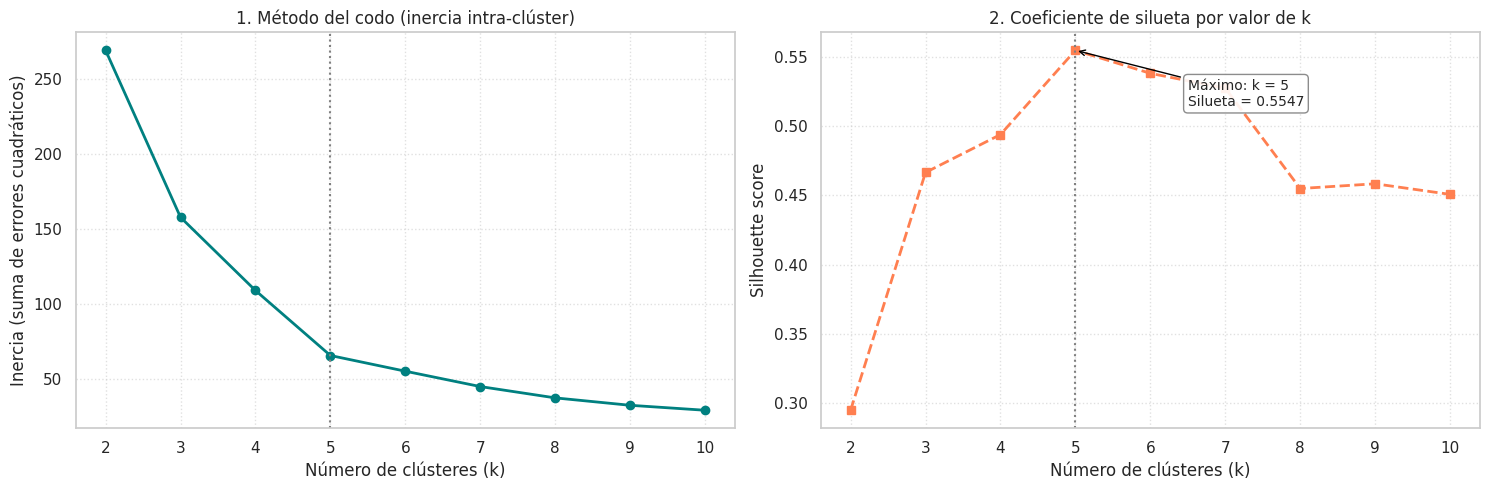

In [10]:
# Graficar el método del codo y la silueta en paralelo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Método del codo
ax1.plot(rango_k, inercias, marker="o", linestyle="-", color="teal", linewidth=2)
ax1.axvline(5, color="gray", linestyle=":", linewidth=1.5)
ax1.set_title("1. Método del codo (inercia intra-clúster)", fontsize=12)
ax1.set_xlabel("Número de clústeres (k)")
ax1.set_ylabel("Inercia (suma de errores cuadráticos)")
ax1.grid(True, linestyle=":", alpha=0.6)

# Gráfico 2: Coeficiente de silueta
ax2.plot(rango_k, scores_silueta, marker="s", linestyle="--", color="coral", linewidth=2)
ax2.axvline(5, color="gray", linestyle=":", linewidth=1.5)
k_max_sil = list(rango_k)[int(np.argmax(scores_silueta))]
ax2.annotate(f"Máximo: k = {k_max_sil}\nSilueta = {max(scores_silueta):.4f}",
             xy=(k_max_sil, max(scores_silueta)), xytext=(k_max_sil + 1.5, max(scores_silueta) - 0.04),
             arrowprops=dict(arrowstyle="->", color="black"), fontsize=10,
             bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.9, edgecolor="gray"))
ax2.set_title("2. Coeficiente de silueta por valor de k", fontsize=12)
ax2.set_xlabel("Número de clústeres (k)")
ax2.set_ylabel("Silhouette score")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

#### **Toma de decisión**

**Método del codo.** La inercia disminuye de 269.0 con *k* = 2 a 157.7 con *k* = 3, a 108.9 con *k* = 4 y a 65.6 con *k* = 5. A partir de ahí la mejora se reduce: pasar a *k* = 6 solo la baja en 10.5 (queda en 55.1), frente a los 43.4 que se ganan al pasar de *k* = 4 a *k* = 5. Por eso el codo se ubica en *k* = 5.

#### **Contraste adicional: ¿y si incluyo la edad?**

Dejé la edad fuera, pero como sí se relaciona con el gasto quiero comprobarlo con datos. Repito la búsqueda de k con las tres variables estandarizadas.

In [11]:
# ==============================================================================
# CONTRASTE: BÚSQUEDA DE K INCLUYENDO LA EDAD COMO TERCERA VARIABLE
# ==============================================================================

X3_scaled = StandardScaler().fit_transform(mall_prep_df[["Edad"] + features_clustering])

scores_silueta_3var = []
for k in rango_k:
    kmeans_3var = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    scores_silueta_3var.append(silhouette_score(X3_scaled, kmeans_3var.fit_predict(X3_scaled)))

comparacion_variables = pd.DataFrame({
    "Silueta (ingreso + puntaje)": scores_silueta,
    "Silueta (con edad)": scores_silueta_3var,
}, index=list(rango_k))
comparacion_variables.index.name = "k"

print("--- SILUETA SEGÚN LAS VARIABLES USADAS ---")
display(comparacion_variables.round(4))

# Qué tanto cambia la partición con k = 5 al agregar la edad
etiquetas_2var = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10).fit_predict(X_scaled)
etiquetas_3var = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10).fit_predict(X3_scaled)
print(f"\n• ARI entre la partición de 2 variables y la de 3 variables (k = 5): "
      f"{adjusted_rand_score(etiquetas_2var, etiquetas_3var):.4f}")

--- SILUETA SEGÚN LAS VARIABLES USADAS ---


,Silueta (ingreso + puntaje),Silueta (con edad)
k,,
2,0.2951,0.3355
3,0.4666,0.3578
4,0.4939,0.4040
5,0.5547,0.4166
6,0.5381,0.4274
7,0.5274,0.4181
8,0.4550,0.4070
9,0.4584,0.3886
10,0.4508,0.4086



• ARI entre la partición de 2 variables y la de 3 variables (k = 5): 0.5845


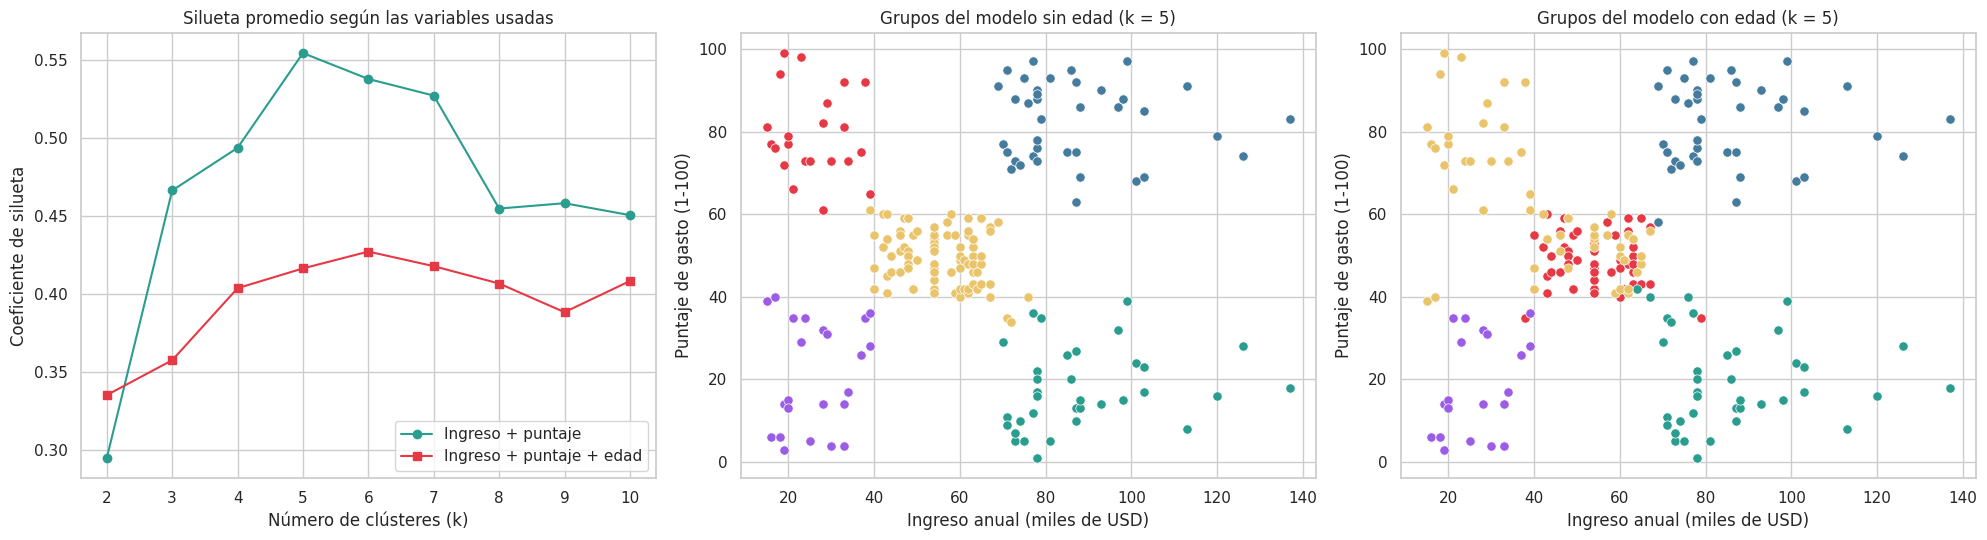

In [12]:
# ==============================================================================
# VISUALIZACIÓN DEL CONTRASTE: SILUETA Y GRUPOS AL AGREGAR LA EDAD
# ==============================================================================

paleta = ["#E63946", "#2A9D8F", "#E9C46A", "#457B9D", "#9B5DE5"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Gráfico 1: silueta promedio para cada k, con y sin la edad
axes[0].plot(list(rango_k), scores_silueta, marker="o", color="#2A9D8F", label="Ingreso + puntaje")
axes[0].plot(list(rango_k), scores_silueta_3var, marker="s", color="#E63946", label="Ingreso + puntaje + edad")
axes[0].set_title("Silueta promedio según las variables usadas")
axes[0].set_xlabel("Número de clústeres (k)")
axes[0].set_ylabel("Coeficiente de silueta")
axes[0].legend()

# Gráficos 2 y 3: mismo plano ingreso-puntaje, coloreado con cada partición (k = 5)
for ax, etiquetas, titulo in [
    (axes[1], etiquetas_2var, "Grupos del modelo sin edad (k = 5)"),
    (axes[2], etiquetas_3var, "Grupos del modelo con edad (k = 5)"),
]:
    for c in range(5):
        mascara = etiquetas == c
        ax.scatter(mall_prep_df.loc[mascara, "Ingreso_Anual_kUSD"],
                   mall_prep_df.loc[mascara, "Puntaje_Gasto"],
                   s=45, color=paleta[c], edgecolor="white", linewidth=0.5, label=f"Grupo {c}")
    ax.set_title(titulo)
    ax.set_xlabel("Ingreso anual (miles de USD)")
    ax.set_ylabel("Puntaje de gasto (1-100)")

plt.tight_layout()
plt.show()

Con la edad la mejor silueta baja a 0.4274 (k = 6) y con k = 5 queda en 0.4166, contra 0.5547 sin ella. Además la partición cambia bastante (ARI de 0.58 entre los dos modelos). La edad vuelve la nube más difusa y los grupos se solapan más. Entonces confirmo el modelo con ingreso y puntaje, y dejo la edad para describir los grupos.

### **Paso 4. Entrenamiento final y visualización de clústeres**

#### **Modelado y representación**

Se realiza el entrenamiento con k = 5 y guardo la etiqueta en una columna nueva. Dibujo los centroides en la escala original con `inverse_transform`, porque en unidades estandarizadas no se leen.

In [13]:
# ==============================================================================
# ENTRENAMIENTO FINAL CON K_OPTIMO
# ==============================================================================

K_OPTIMO = 5
kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=SEMILLA, n_init=10)
mall_prep_df["Cluster_KM"] = kmeans_final.fit_predict(X_scaled)

score_final = silhouette_score(X_scaled, mall_prep_df["Cluster_KM"])

print("--- RESULTADO DEL MODELO FINAL ---")
print(f"• Número de clústeres seleccionado (k): {K_OPTIMO}")
print(f"• Coeficiente de silueta final:         {score_final:.4f}")
print(f"• Inercia final:                        {kmeans_final.inertia_:.2f}")
print("\nClientes por clúster:")
print(mall_prep_df["Cluster_KM"].value_counts().sort_index())

# Estabilidad frente a la semilla: otras inicializaciones deberían dar la misma partición
print("\n--- ESTABILIDAD FRENTE A LA SEMILLA (ARI contra el modelo final) ---")
for semilla_prueba in [0, 1, 42, 999]:
    etiquetas_prueba = KMeans(n_clusters=K_OPTIMO, random_state=semilla_prueba, n_init=10).fit_predict(X_scaled)
    print(f"• random_state = {semilla_prueba:<4}: ARI = {adjusted_rand_score(mall_prep_df['Cluster_KM'], etiquetas_prueba):.4f}")

--- RESULTADO DEL MODELO FINAL ---
• Número de clústeres seleccionado (k): 5
• Coeficiente de silueta final:         0.5547
• Inercia final:                        65.57

Clientes por clúster:
Cluster_KM
0    22
1    35
2    81
3    39
4    23
Name: count, dtype: int64

--- ESTABILIDAD FRENTE A LA SEMILLA (ARI contra el modelo final) ---
• random_state = 0   : ARI = 1.0000
• random_state = 1   : ARI = 1.0000
• random_state = 42  : ARI = 1.0000
• random_state = 999 : ARI = 1.0000


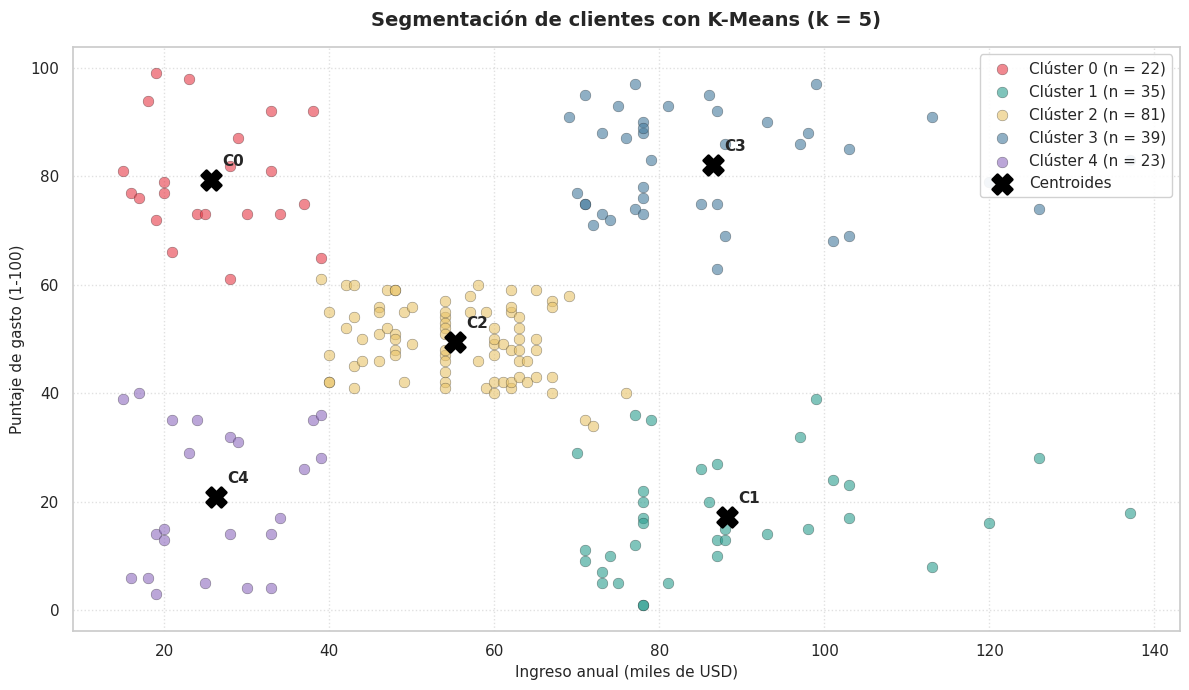

--- CENTROIDES EN ESCALA ORIGINAL ---


,Ingreso_Anual_kUSD,Puntaje_Gasto
Clúster,,
0,25.73,79.36
1,88.20,17.11
2,55.30,49.52
3,86.54,82.13
4,26.30,20.91


In [14]:
# ==============================================================================
# VISUALIZACIÓN DE CLÚSTERES Y CENTROIDES (ESCALA ORIGINAL)
# ==============================================================================

colores = {0: "#E63946", 1: "#2A9D8F", 2: "#E9C46A", 3: "#457B9D", 4: "#8E6BBF"}

# Centroides transformados de vuelta a la escala original
centroides_originales = escalador.inverse_transform(kmeans_final.cluster_centers_)

fig, ax = plt.subplots(figsize=(12, 7))

for cluster_id in range(K_OPTIMO):
    puntos = mall_prep_df[mall_prep_df["Cluster_KM"] == cluster_id]
    ax.scatter(puntos["Ingreso_Anual_kUSD"], puntos["Puntaje_Gasto"], color=colores[cluster_id],
               alpha=0.6, edgecolor="k", linewidth=0.3, s=60,
               label=f"Clúster {cluster_id} (n = {len(puntos)})")

ax.scatter(centroides_originales[:, 0], centroides_originales[:, 1], color="black", marker="X",
           s=200, linewidths=2, zorder=10, label="Centroides")

# Número de clúster junto a cada centroide
for cluster_id in range(K_OPTIMO):
    ax.annotate(f"C{cluster_id}", xy=(centroides_originales[cluster_id, 0], centroides_originales[cluster_id, 1]),
                xytext=(8, 10), textcoords="offset points", fontsize=11, fontweight="bold")

ax.set_title("Segmentación de clientes con K-Means (k = 5)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Ingreso anual (miles de USD)", fontsize=11)
ax.set_ylabel("Puntaje de gasto (1-100)", fontsize=11)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print("--- CENTROIDES EN ESCALA ORIGINAL ---")
display(pd.DataFrame(centroides_originales, columns=features_clustering).round(2).rename_axis("Clúster"))

#### **Interpretación preliminar**

Para identificar las observaciones frontera, calculo el coeficiente de silueta de cada cliente. Un valor bajo (cercano a 0) indica que el cliente queda entre dos grupos, y un valor negativo, que está más cerca de otro grupo que del suyo.

--- SILUETA INDIVIDUAL ---
• Clientes con silueta negativa: 2
• Clientes con silueta menor a 0.25: 11

Silueta promedio por clúster:
Cluster_KM
0    0.598
1    0.505
2    0.598
3    0.511
4    0.511
Name: Silueta_Individual, dtype: float64

Los 6 clientes peor ubicados:


,Edad,Ingreso_Anual_kUSD,Puntaje_Gasto,Cluster_KM,Silueta_Individual
146,48,77,36,1,-0.029
42,48,39,36,4,-0.012
124,23,70,29,1,0.008
45,24,39,65,0,0.050
40,65,38,35,4,0.091
160,56,79,35,1,0.097


Los dos clientes con ingreso atípico (137 mil USD):


,Edad,Ingreso_Anual_kUSD,Puntaje_Gasto,Cluster_KM,Silueta_Individual
198,32,137,18,1,0.388
199,30,137,83,3,0.373


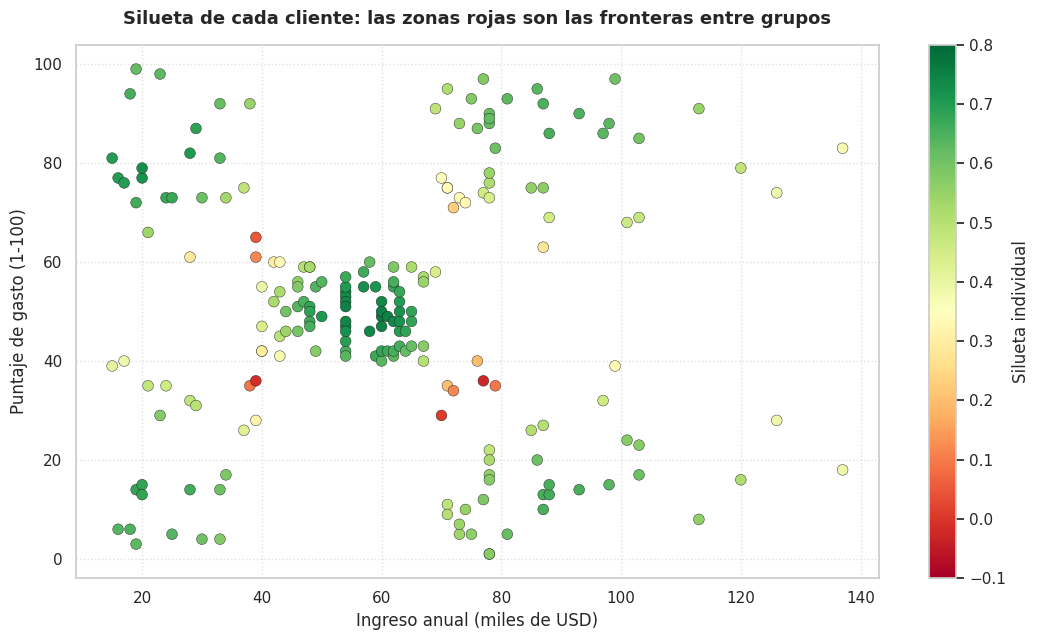

In [15]:
# ==============================================================================
# OBSERVACIONES FRONTERA: SILUETA INDIVIDUAL
# ==============================================================================

mall_prep_df["Silueta_Individual"] = silhouette_samples(X_scaled, mall_prep_df["Cluster_KM"])

print("--- SILUETA INDIVIDUAL ---")
print(f"• Clientes con silueta negativa: {(mall_prep_df['Silueta_Individual'] < 0).sum()}")
print(f"• Clientes con silueta menor a 0.25: {(mall_prep_df['Silueta_Individual'] < 0.25).sum()}")

print("\nSilueta promedio por clúster:")
print(mall_prep_df.groupby("Cluster_KM")["Silueta_Individual"].mean().round(3))

print("\nLos 6 clientes peor ubicados:")
display(mall_prep_df.nsmallest(6, "Silueta_Individual")[["Edad", "Ingreso_Anual_kUSD", "Puntaje_Gasto", "Cluster_KM", "Silueta_Individual"]].round(3))

print("Los dos clientes con ingreso atípico (137 mil USD):")
display(mall_prep_df[mall_prep_df["Ingreso_Anual_kUSD"] == 137][["Edad", "Ingreso_Anual_kUSD", "Puntaje_Gasto", "Cluster_KM", "Silueta_Individual"]].round(3))

# Mapa de calor de la silueta sobre el plano ingreso-puntaje
fig, ax = plt.subplots(figsize=(11, 6.5))
sc = ax.scatter(mall_prep_df["Ingreso_Anual_kUSD"], mall_prep_df["Puntaje_Gasto"],
                c=mall_prep_df["Silueta_Individual"], cmap="RdYlGn", vmin=-0.1, vmax=0.8,
                s=60, edgecolor="k", linewidth=0.3)
plt.colorbar(sc, ax=ax, label="Silueta individual")
ax.set_title("Silueta de cada cliente: las zonas rojas son las fronteras entre grupos", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Ingreso anual (miles de USD)")
ax.set_ylabel("Puntaje de gasto (1-100)")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

El modelo final tiene silueta 0.5547, una separación buena. Cuatro grupos quedan en las esquinas del plano (ingreso bajo con gasto bajo, bajo con alto, alto con bajo y alto con alto) y el más grande queda al centro. Los tamaños son 22, 35, 81, 39 y 23 clientes.

Los solapes están en el centro. Solo dos clientes tienen silueta negativa y once quedan por debajo de 0.25, con ingresos entre 38 y 79 mil y puntajes entre 29 y 65. Son clientes que podrían estar en dos grupos, y en la Parte 2 veo que son los que cambian con otro algoritmo. Los dos clientes de ingreso atípico (137 mil) quedaron en los grupos de ingreso alto que les tocan, con siluetas de 0.39 y 0.37, así que no distorsionaron los centroides.

Con otras cuatro semillas sale la misma partición (ARI de 1.0), o sea que no depende del azar.

### **Resumen de la Parte 1**

Los datos no tienen nulos ni duplicados y conservé los dos atípicos. Elegí ingreso y puntaje de gasto y los estandaricé. El codo y la silueta coinciden en k = 5, y el modelo final tiene silueta 0.5547 y es estable con distintas semillas. La edad empeoraba la separación y la dejé para describir los grupos.

## **Parte 2. Clustering jerárquico, comparación y perfiles**

Esta parte continúa el procedimiento de la Parte 1 y reutiliza `X_scaled`, `mall_prep_df`, `escalador` y las etiquetas de K-Means. Primero construyo el árbol jerárquico, luego lo comparo con K-Means, elaboro los perfiles de cada grupo en unidades reales y, finalmente, defino los segmentos.

### **Paso 1. Modelado jerárquico aglomerativo y análisis de dendrogramas**

#### **Construcción de dendrogramas**

Parto del mismo `X_scaled` para que cualquier diferencia venga del algoritmo y no de los datos. El método aglomerativo empieza con cada cliente solo y va uniendo los dos grupos más cercanos; qué es "cercano" depende del enlace. Comparo tres:

- **Ward:** une los grupos que menos aumentan la varianza interna (lo mismo que K-Means intenta minimizar).
- **Completo:** usa la distancia entre los dos puntos más lejanos de los grupos.
- **Promedio:** usa la distancia media entre todos los pares de puntos.

Dibujo los dendrogramas truncados a las últimas 30 fusiones, porque con 200 clientes la parte baja se vuelve ilegible. El eje vertical es la distancia a la que ocurre cada fusión. La línea roja marca el corte en cinco grupos.

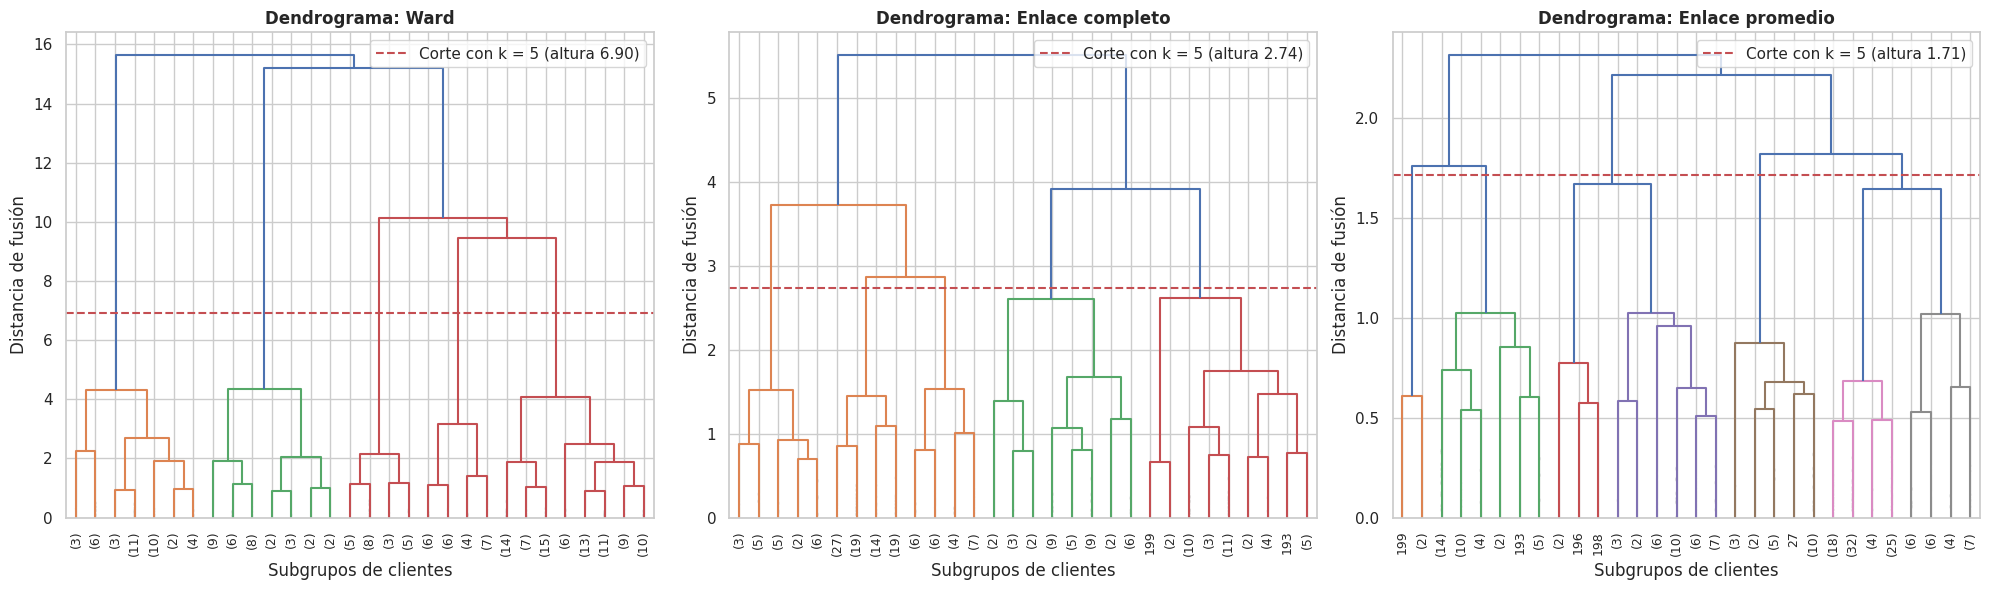

In [17]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# ==============================================================================
# CONSTRUCCIÓN DE LOS DENDROGRAMAS (WARD, COMPLETO Y PROMEDIO)
# ==============================================================================

metodos_enlace = ["ward", "complete", "average"]
nombres_enlace = {"ward": "Ward", "complete": "Enlace completo", "average": "Enlace promedio"}

# Estructura jerárquica (el árbol) para cada criterio de enlace
matrices_enlace = {metodo: linkage(X_scaled, method=metodo) for metodo in metodos_enlace}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, metodo in zip(axes, metodos_enlace):
    Z = matrices_enlace[metodo]
    plt.sca(ax)
    dendrogram(
        Z,
        truncate_mode="lastp",  # muestra únicamente las últimas uniones (las más importantes) de la jerarquía
        p=30,
        leaf_rotation=90.0,
        leaf_font_size=9.0,
        show_contracted=True,
    )
    # Altura de corte que deja exactamente 5 grupos: punto medio entre la fusión que se deshace y la última que se conserva
    altura_corte = (Z[-4, 2] + Z[-5, 2]) / 2
    ax.axhline(y=altura_corte, color="r", linestyle="--", label=f"Corte con k = 5 (altura {altura_corte:.2f})")
    ax.set_title(f"Dendrograma: {nombres_enlace[metodo]}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Subgrupos de clientes")
    ax.set_ylabel("Distancia de fusión")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

#### **Corte del árbol jerárquico**

Para no tomar una decicion solo mirando el dibujo, mido los saltos verticales: el hueco entre la altura de la fusión que deshago y la de la última que conservo. Mientras más grande, más natural es el corte. También calculo la silueta de cada enlace para k de 3 a 6 y agrego el enlace simple como referencia.

In [18]:
# ==============================================================================
# ANÁLISIS DE LAS ALTURAS DE FUSIÓN (SALTOS VERTICALES DEL DENDROGRAMA)
# ==============================================================================

saltos = {}
for metodo in metodos_enlace:
    Z = matrices_enlace[metodo]
    saltos[nombres_enlace[metodo]] = {k: Z[-(k - 1), 2] - Z[-k, 2] for k in range(2, 10)}

tabla_saltos = pd.DataFrame(saltos)
tabla_saltos.index.name = "k"

print("--- SALTO VERTICAL SEGÚN EL NÚMERO DE GRUPOS DEL CORTE ---")
display(tabla_saltos.round(2))
print("k con el mayor salto en cada enlace:")
print(tabla_saltos.idxmax())

# ==============================================================================
# SILUETA POR ENLACE Y NÚMERO DE GRUPOS
# ==============================================================================

resultados_enlace = []
for metodo in ["ward", "complete", "average", "single"]:
    for k in range(3, 7):
        etiquetas_hc = AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage=metodo).fit_predict(X_scaled)
        resultados_enlace.append({"Enlace": metodo, "k": k, "Silueta": silhouette_score(X_scaled, etiquetas_hc)})

tabla_enlaces = pd.DataFrame(resultados_enlace).pivot(index="k", columns="Enlace", values="Silueta")
print("\n--- SILUETA POR ENLACE Y NÚMERO DE GRUPOS ---")
display(tabla_enlaces[["ward", "complete", "average", "single"]].round(4))

# Tamaño de los grupos con enlace simple y promedio (k = 5)
for metodo in ["single", "average"]:
    tamanos = np.bincount(AgglomerativeClustering(n_clusters=5, linkage=metodo).fit_predict(X_scaled))
    print(f"• Tamaño de los 5 grupos con enlace {metodo}: {sorted(tamanos, reverse=True)}")

--- SALTO VERTICAL SEGÚN EL NÚMERO DE GRUPOS DEL CORTE ---


,Ward,Enlace completo,Enlace promedio
k,,,
2,0.44,1.59,0.10
3,5.04,0.18,0.40
4,0.69,0.86,0.06
5,5.10,0.25,0.09
6,0.05,0.01,0.02
7,0.24,0.86,0.62
8,0.92,0.07,0.00
9,0.45,0.15,0.01


k con el mayor salto en cada enlace:
Ward               5
Enlace completo    2
Enlace promedio    7
dtype: int64

--- SILUETA POR ENLACE Y NÚMERO DE GRUPOS ---


Enlace,ward,complete,average,single
k,,,,
3,0.4610,0.4666,0.4666,0.3613
4,0.4926,0.4959,0.4959,0.3041
5,0.5538,0.5531,0.4794,0.2758
6,0.5387,0.5441,0.4654,0.2798


• Tamaño de los 5 grupos con enlace single: [np.int64(195), np.int64(2), np.int64(1), np.int64(1), np.int64(1)]
• Tamaño de los 5 grupos con enlace average: [np.int64(102), np.int64(38), np.int64(36), np.int64(21), np.int64(3)]


Ward es el único con un corte claro. Sus últimas fusiones están en 15.62, 15.19, 10.14 y 9.45, y después cae a 4.35: ese salto de 5.10 es el mayor y cortarlo deja cinco grupos. Hay otro salto casi igual (5.04) que daría tres grupos, pero con tres la silueta es 0.461 contra 0.5538 con cinco, así que lo descarto.

En el enlace completo los saltos son pequeños (el mayor, 1.59, da dos grupos) y en el promedio tampoco hay un hueco claro en cinco. Eso no quiere decir que no encuentren estructura: el completo con k = 5 tiene silueta 0.5531, casi igual a Ward, pero su dendrograma no justifica el corte por sí solo. El promedio baja a 0.4794 porque deja un grupo de 3 clientes, y el simple hace encadenamiento: un grupo de 195 clientes y cuatro de uno o dos, con silueta 0.28.

Corto Ward en k = 5. Coincide con K-Means, tiene el corte más claro y la mejor silueta (empatada con el completo), y usa el mismo criterio de varianza que K-Means, así que la comparación es más limpia.

In [19]:
# ==============================================================================
# MODELO JERÁRQUICO FINAL (WARD, k = 5)
# ==============================================================================

hc = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage="ward")
mall_prep_df["Cluster_HC"] = hc.fit_predict(X_scaled)

score_hc = silhouette_score(X_scaled, mall_prep_df["Cluster_HC"])

print("--- RESULTADO DEL CLUSTERING JERÁRQUICO ---")
print(f"• Número de grupos: 5 (enlace Ward, distancia euclidiana)")
print(f"• Coeficiente de silueta (jerárquico): {score_hc:.4f}")
print(f"• Coeficiente de silueta (K-Means):    {score_final:.4f}")
print("\nClientes por grupo jerárquico:")
print(mall_prep_df["Cluster_HC"].value_counts().sort_index())

--- RESULTADO DEL CLUSTERING JERÁRQUICO ---
• Número de grupos: 5 (enlace Ward, distancia euclidiana)
• Coeficiente de silueta (jerárquico): 0.5538
• Coeficiente de silueta (K-Means):    0.5547

Clientes por grupo jerárquico:
Cluster_HC
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


### **Paso 2. Comparación metodológica: K-Means contra jerárquico**

#### **Cruce de asignaciones**

Los números de grupo son arbitrarios: el 0 de K-Means no tiene por qué ser el 0 del jerárquico. Por eso cruzo las etiquetas con una tabla de contingencia. Primero la muestro tal cual y después renumero los grupos jerárquicos con el grupo de K-Means con el que más coinciden, para que quede la diagonal. Eso es solo una etiqueta y no cambia el ARI.

#### **Métrica de concordancia**

Calculo el índice de Rand ajustado (ARI), que mide el acuerdo entre dos particiones sin importar la numeración: 1 es idéntico y cerca de 0 es como el azar.

--- TABLA DE CONTINGENCIA (ETIQUETAS ORIGINALES) ---


K-Means,0,1,2,3,4
Jerárquico,,,,,
0,0,32,0,0,0
1,0,0,0,39,0
2,1,3,81,0,0
3,21,0,0,0,0
4,0,0,0,0,23



--- CONCORDANCIA ENTRE LOS DOS ALGORITMOS ---
• Adjusted Rand Index (ARI): 0.9420
• Clientes en grupos equivalentes: 196 de 200 (98.0%)


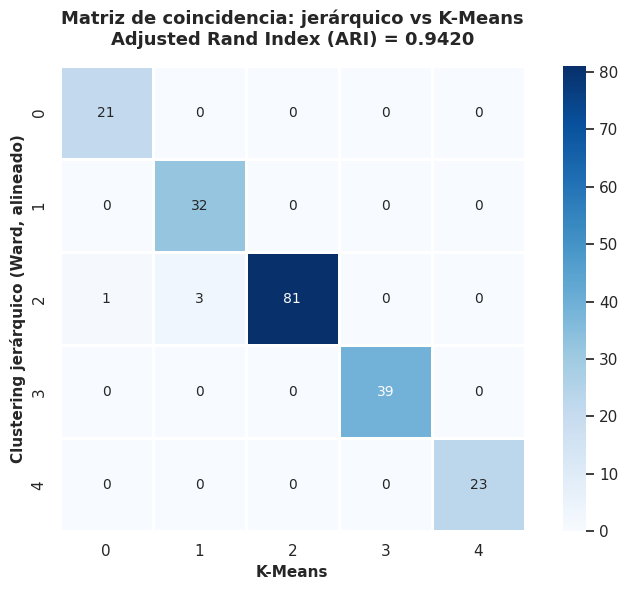

In [20]:
# ==============================================================================
# TABLA DE CONTINGENCIA Y ÍNDICE DE RAND AJUSTADO (ARI)
# ==============================================================================

# Tabla cruzada con las etiquetas originales (numeración arbitraria)
tabla_cruzada = pd.crosstab(mall_prep_df["Cluster_HC"], mall_prep_df["Cluster_KM"],
                            rownames=["Jerárquico"], colnames=["K-Means"])
print("--- TABLA DE CONTINGENCIA (ETIQUETAS ORIGINALES) ---")
display(tabla_cruzada)

# Alineación: cada grupo jerárquico toma el número del grupo de K-Means con el que más coincide
mapeo_alineacion = tabla_cruzada.idxmax(axis=1).to_dict()
assert len(set(mapeo_alineacion.values())) == 5, "La alineación debe ser uno a uno"
mall_prep_df["Cluster_HC_alineado"] = mall_prep_df["Cluster_HC"].map(mapeo_alineacion)

matriz_ordenada = pd.crosstab(mall_prep_df["Cluster_HC_alineado"], mall_prep_df["Cluster_KM"],
                              rownames=["Jerárquico (alineado)"], colnames=["K-Means"])

# Cálculo del Adjusted Rand Index (ARI)
ari = adjusted_rand_score(mall_prep_df["Cluster_KM"], mall_prep_df["Cluster_HC"])
coinciden = (mall_prep_df["Cluster_KM"] == mall_prep_df["Cluster_HC_alineado"]).sum()

print("\n--- CONCORDANCIA ENTRE LOS DOS ALGORITMOS ---")
print(f"• Adjusted Rand Index (ARI): {ari:.4f}")
print(f"• Clientes en grupos equivalentes: {coinciden} de {len(mall_prep_df)} ({coinciden / len(mall_prep_df) * 100:.1f}%)")

# Visualización con Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_ordenada, annot=True, fmt="d", cmap="Blues", cbar=True, linewidths=0.8, linecolor="white", square=True)
plt.title(f"Matriz de coincidencia: jerárquico vs K-Means\nAdjusted Rand Index (ARI) = {ari:.4f}",
          fontsize=13, fontweight="bold", pad=15)
plt.xlabel("K-Means", fontsize=11, fontweight="bold")
plt.ylabel("Clustering jerárquico (Ward, alineado)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

In [21]:
# ==============================================================================
# ¿QUÉ CLIENTES CAMBIAN DE GRUPO?
# ==============================================================================

cambian = mall_prep_df[mall_prep_df["Cluster_KM"] != mall_prep_df["Cluster_HC_alineado"]].copy()

# Posición de cada uno en el ranking de menor silueta (1 = el peor ubicado de los 200)
ranking_silueta = mall_prep_df["Silueta_Individual"].rank(method="first").astype(int)
cambian["Puesto_menor_silueta"] = ranking_silueta.loc[cambian.index]

print("--- CLIENTES QUE CAMBIAN DE GRUPO ENTRE ALGORITMOS ---")
display(cambian[["Edad", "Ingreso_Anual_kUSD", "Puntaje_Gasto", "Cluster_KM", "Cluster_HC_alineado",
                 "Silueta_Individual", "Puesto_menor_silueta"]].round(3))

# ==============================================================================
# CONCORDANCIA CON K-MEANS SEGÚN EL CRITERIO DE ENLACE (k = 5)
# ==============================================================================

ari_enlaces = {}
for metodo in ["ward", "complete", "average", "single"]:
    etiquetas_hc = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage=metodo).fit_predict(X_scaled)
    ari_enlaces[metodo] = adjusted_rand_score(mall_prep_df["Cluster_KM"], etiquetas_hc)

print("--- ARI CONTRA K-MEANS SEGÚN EL ENLACE ---")
print(pd.Series(ari_enlaces).round(4).to_string())

--- CLIENTES QUE CAMBIAN DE GRUPO ENTRE ALGORITMOS ---


,Edad,Ingreso_Anual_kUSD,Puntaje_Gasto,Cluster_KM,Cluster_HC_alineado,Silueta_Individual,Puesto_menor_silueta
45,24,39,65,0,2,0.050,4
124,23,70,29,1,2,0.008,3
146,48,77,36,1,2,-0.029,1
160,56,79,35,1,2,0.097,6


--- ARI CONTRA K-MEANS SEGÚN EL ENLACE ---
ward        0.9420
complete    0.9417
average     0.7170
single      0.0102


#### **Análisis comparativo**

El ARI es 0.942: 196 de 200 clientes quedan en grupos equivalentes (98 %). Dos algoritmos con lógicas distintas llegan a los mismos cinco segmentos, así que los grupos están en los datos y no son un efecto del método. El completo da algo parecido (ARI 0.94), el promedio baja a 0.72 y el simple casi no coincide (0.01), igual que en los dendrogramas.

Los cuatro clientes que cambian son de frontera: uno de 24 años con ingreso de 39 mil y puntaje 65, y tres de ingreso alto con gasto bajo o medio (23 años con 70 mil y puntaje 29, 48 años con 77 mil y 36, y 56 años con 79 mil y 35). El jerárquico manda los cuatro al grupo central. Están entre los seis de menor silueta, o sea que los algoritmos discrepan justo donde ya sabía que había ambigüedad. Tiene sentido: K-Means asigna al centroide más cercano y Ward decide por cuánto sube la varianza al fusionar.

La elección entre los dos no cambia la segmentación. Para los perfiles uso K-Means, que además permite asignar un cliente nuevo calculando el centroide más cercano, algo que el árbol no hace sin reconstruirse.

### **Paso 3. Perfilamiento de clústeres en escala original**

#### **Reconstrucción de perfiles**

Un perfil expresado en desviaciones estándar no resulta útil para un gerente, así que asocio las etiquetas de K-Means con las variables en sus unidades reales y calculo la media y la mediana de la edad, el ingreso y el puntaje de gasto por grupo. Muestro ambas medidas porque, si difieren mucho, el grupo es heterogéneo o tiene valores extremos. `Edad` y `Genero`, que no participaron en el modelo, me permiten describir quiénes integran cada grupo.

In [22]:
# ==============================================================================
# PERFILAMIENTO Y CÁLCULO DE MÉTRICAS DE NEGOCIO (ESCALA ORIGINAL)
# ==============================================================================

columnas_perfil = ["Edad", "Ingreso_Anual_kUSD", "Puntaje_Gasto"]

# Agrupamiento y estadísticos por clúster
perfil_medias = mall_prep_df.groupby("Cluster_KM")[columnas_perfil].mean().round(2)
perfil_medianas = mall_prep_df.groupby("Cluster_KM")[columnas_perfil].median().round(2)

perfil_clusters = perfil_medias.add_suffix("_media").join(perfil_medianas.add_suffix("_mediana"))
perfil_clusters = perfil_clusters[["Edad_media", "Edad_mediana", "Ingreso_Anual_kUSD_media", "Ingreso_Anual_kUSD_mediana",
                                   "Puntaje_Gasto_media", "Puntaje_Gasto_mediana"]]

# Métricas de volumen y composición por género
perfil_clusters["Conteo_Clientes"] = mall_prep_df["Cluster_KM"].value_counts()
perfil_clusters["Porcentaje_Base_%"] = (mall_prep_df["Cluster_KM"].value_counts(normalize=True) * 100).round(2)
perfil_clusters["Mujeres_%"] = (mall_prep_df.groupby("Cluster_KM")["Genero"].apply(lambda x: (x == "Female").mean() * 100)).round(2)

print("=" * 100)
print("                    PERFILAMIENTO DE CLÚSTERS (K-MEANS, ESCALA ORIGINAL)")
print("=" * 100)
print(perfil_clusters.to_string())
print("=" * 100)

# Perfil del modelo jerárquico (etiquetas alineadas) para verificar que cuenta la misma historia
perfil_hc_medias = mall_prep_df.groupby("Cluster_HC_alineado")[columnas_perfil].mean().round(2)
print("\nPerfil promedio con el clustering jerárquico (para contraste):")
print(perfil_hc_medias.to_string())

                    PERFILAMIENTO DE CLÚSTERS (K-MEANS, ESCALA ORIGINAL)
            Edad_media  Edad_mediana  Ingreso_Anual_kUSD_media  Ingreso_Anual_kUSD_mediana  Puntaje_Gasto_media  Puntaje_Gasto_mediana  Conteo_Clientes  Porcentaje_Base_%  Mujeres_%
Cluster_KM                                                                                                                                                                           
0                25.27          23.5                     25.73                        24.5                79.36                   77.0               22               11.0      59.09
1                41.11          42.0                     88.20                        85.0                17.11                   16.0               35               17.5      45.71
2                42.72          46.0                     55.30                        54.0                49.52                   50.0               81               40.5      59.26
3                

#### **Visualización comparativa**

Diagramas de caja por clúster y un mapa de calor con los perfiles promedio, para comparar los grupos de un vistazo.

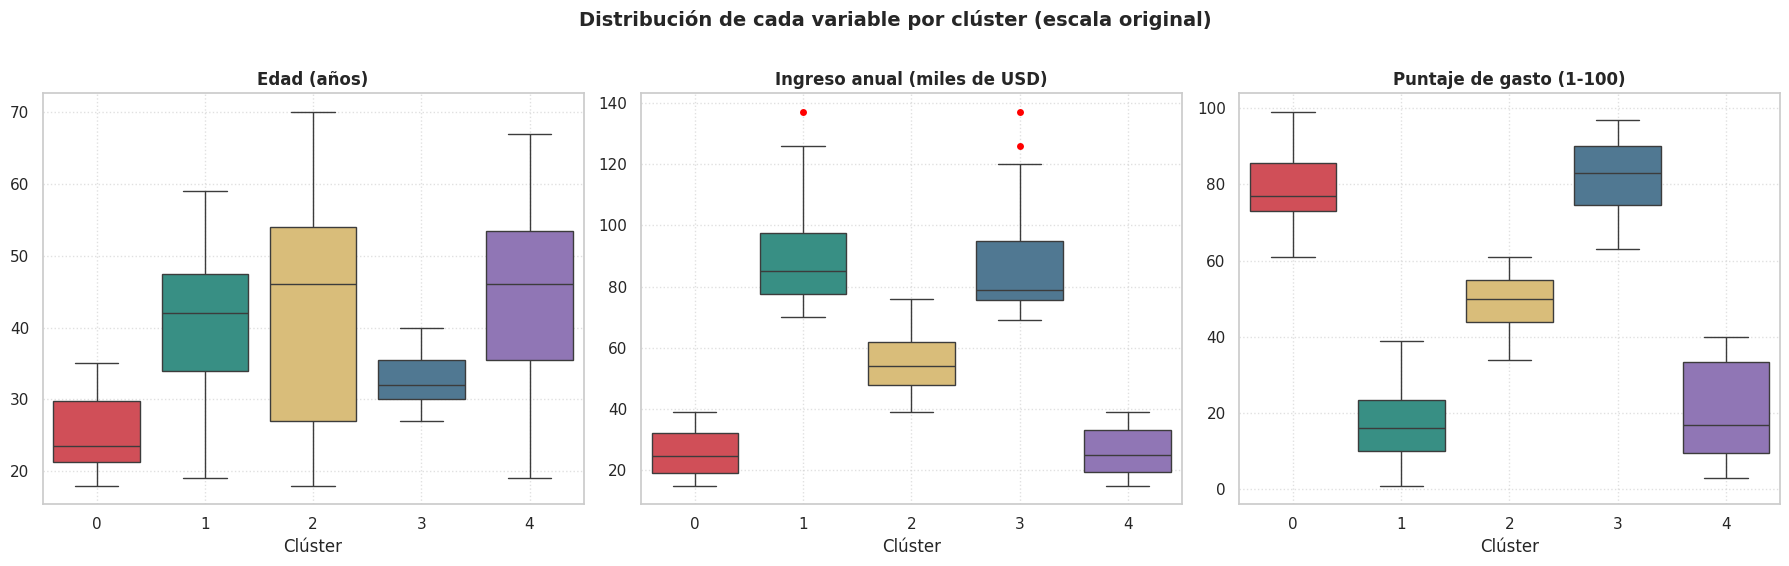

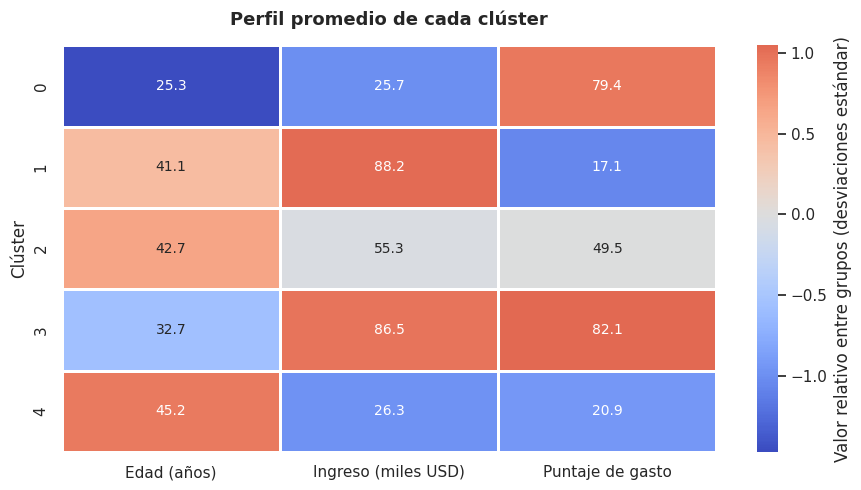

In [23]:
# ==============================================================================
# VISUALIZACIÓN COMPARATIVA DE LOS PERFILES
# ==============================================================================

# Diagramas de caja por clúster: dispersión interna y solapamiento entre grupos
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, col in zip(axes, columnas_perfil):
    sns.boxplot(data=mall_prep_df, x="Cluster_KM", y=col, hue="Cluster_KM", palette=colores, legend=False,
                ax=ax, flierprops=dict(marker="o", markerfacecolor="red", markeredgecolor="none", markersize=5))
    ax.set_title(etiquetas_ejes[col], fontsize=12, fontweight="bold")
    ax.set_xlabel("Clúster")
    ax.set_ylabel("")
    ax.grid(True, linestyle=":", alpha=0.6)

plt.suptitle("Distribución de cada variable por clúster (escala original)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Mapa de calor de perfiles promedio: el color es el valor relativo entre grupos, el número es el promedio real
perfil_relativo = (perfil_medias - perfil_medias.mean()) / perfil_medias.std()

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(perfil_relativo, annot=perfil_medias, fmt=".1f", cmap="coolwarm", center=0,
            linewidths=0.8, linecolor="white", ax=ax,
            cbar_kws={"label": "Valor relativo entre grupos (desviaciones estándar)"})
ax.set_title("Perfil promedio de cada clúster", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("")
ax.set_ylabel("Clúster")
ax.set_xticklabels(["Edad (años)", "Ingreso (miles USD)", "Puntaje de gasto"], rotation=0)
plt.tight_layout()
plt.show()

Los perfiles de los cinco grupos son los siguientes:

- **Clúster 0:** 22 clientes (11 %). Son muy jóvenes (edad media de 25.3 años y mediana de 23.5), con ingreso bajo (25.7 mil dólares) y gasto muy alto (puntaje de 79.4).
- **Clúster 1:** 35 clientes (17.5 %). Tienen una edad media de 41.1 años, ingreso alto (88.2 mil dólares) y gasto muy bajo (puntaje de 17.1).
- **Clúster 2:** 81 clientes (40.5 %). Tienen una edad media de 42.7 años, ingreso medio (55.3 mil dólares) y un puntaje de gasto de 49.5. Es el grupo más grande y el de edades más dispersas (de 18 a 70 años).
- **Clúster 3:** 39 clientes (19.5 %). Tienen una edad media de 32.7 años, ingreso alto (86.5 mil dólares) y gasto alto (puntaje de 82.1).
- **Clúster 4:** 23 clientes (11.5 %). Tienen una edad media de 45.2 años, ingreso bajo (26.3 mil dólares) y gasto bajo (puntaje de 20.9).

En los diagramas de caja, la dispersión dentro de cada grupo es pequeña frente a la distancia entre grupos, por lo que quedan bien separados en las dos variables del modelo (ingreso y puntaje de gasto). La edad es la variable donde más se solapan, lo que respalda no haberla usado para segmentar; aun así, describe bien a los grupos: los que más gastan (clústeres 0 y 3) son los más jóvenes. Además, las medias y las medianas son muy parecidas, así que ningún grupo está distorsionado por valores extremos. El género tampoco distingue grupos, pues el porcentaje de mujeres está entre 46 % y 61 % en todos. Finalmente, el perfil obtenido con el clustering jerárquico es prácticamente igual.

### **Paso 4. Caracterización comercial y resumen ejecutivo**

#### **Segmentos**

Para nombrar los segmentos definí una regla en vez de ponerlos a mano, así el nombre depende del perfil y no del número de clúster, que puede cambiar entre ejecuciones. Ingreso alto es 70 mil o más y bajo es 40 mil o menos; gasto alto es un puntaje de 60 o más y bajo de 40 o menos. Fijé los umbrales mirando los perfiles y ningún grupo queda cerca del límite. El grupo central no entra en ninguna esquina a propósito. Después armo un mapa estratégico (estrategia, objetivo y prioridad) y lo uno al perfil en una sola tabla.

In [24]:
# ==============================================================================
# NOMBRES COMERCIALES POR SEGMENTO (REGLA SOBRE EL PERFIL PROMEDIO)
# ==============================================================================

def nombrar_segmento(ingreso, gasto):
    """Asigna un nombre comercial según el ingreso y el puntaje de gasto promedio del clúster."""
    if ingreso >= 70 and gasto >= 60:
        return "Clientes objetivo de alto valor"
    elif ingreso >= 70 and gasto <= 40:
        return "Ahorradores de alto ingreso"
    elif ingreso <= 40 and gasto >= 60:
        return "Compradores impulsivos"
    elif ingreso <= 40 and gasto <= 40:
        return "Clientes austeros"
    else:
        return "Clientes promedio"

nombres_segmento = {
    cluster_id: nombrar_segmento(perfil_medias.loc[cluster_id, "Ingreso_Anual_kUSD"],
                                 perfil_medias.loc[cluster_id, "Puntaje_Gasto"])
    for cluster_id in perfil_medias.index
}
assert len(set(nombres_segmento.values())) == K_OPTIMO, "Cada clúster debe recibir un nombre distinto"

mall_prep_df["Segmento"] = mall_prep_df["Cluster_KM"].map(nombres_segmento)

# Mapa estratégico: una estrategia, un objetivo medible y una prioridad por segmento
mapa_estrategico = {
    "Clientes objetivo de alto valor": {
        "Estrategia Comercial": "Fidelización premium: preventas, atención preferencial y beneficios exclusivos",
        "Objetivo Medible": "Mantener frecuencia de visita y ticket promedio; evitar la fuga",
        "Prioridad": "Alta",
    },
    "Ahorradores de alto ingreso": {
        "Estrategia Comercial": "Activación: eventos, lanzamientos y experiencias que den a conocer la oferta (sin descuentos)",
        "Objetivo Medible": "Subir el puntaje de gasto promedio desde 17 hacia el nivel de los clientes de alto valor",
        "Prioridad": "Alta",
    },
    "Compradores impulsivos": {
        "Estrategia Comercial": "Promociones de corto plazo, cupones y campañas en redes, con tope de gasto responsable",
        "Objetivo Medible": "Aumentar la frecuencia de visita sin empujar compras que superen su capacidad",
        "Prioridad": "Media",
    },
    "Clientes promedio": {
        "Estrategia Comercial": "Programa de puntos básico y ofertas generales por temporada",
        "Objetivo Medible": "Mover a una parte del grupo hacia mayor gasto (venta cruzada)",
        "Prioridad": "Media",
    },
    "Clientes austeros": {
        "Estrategia Comercial": "Comunicación masiva de bajo costo, sin descuentos profundos",
        "Objetivo Medible": "Mantener la visita al menor costo posible",
        "Prioridad": "Baja",
    },
}

# Convertir el mapa estratégico a DataFrame y combinarlo con el perfil
df_estrategia = pd.DataFrame.from_dict(mapa_estrategico, orient="index")

tabla_final = perfil_clusters.copy()
tabla_final["Nombre Segmento"] = tabla_final.index.map(nombres_segmento)
tabla_final = tabla_final.merge(df_estrategia, left_on="Nombre Segmento", right_index=True)

columnas_presentacion = ["Nombre Segmento", "Conteo_Clientes", "Porcentaje_Base_%", "Edad_media",
                         "Ingreso_Anual_kUSD_media", "Puntaje_Gasto_media", "Prioridad", "Estrategia Comercial"]

print("=" * 150)
print("MATRIZ FINAL: SEGMENTACIÓN DE CLIENTES VINCULADA A LA ESTRATEGIA COMERCIAL")
print("=" * 150)
print(tabla_final[columnas_presentacion].to_string())
print("=" * 150)

MATRIZ FINAL: SEGMENTACIÓN DE CLIENTES VINCULADA A LA ESTRATEGIA COMERCIAL
                            Nombre Segmento  Conteo_Clientes  Porcentaje_Base_%  Edad_media  Ingreso_Anual_kUSD_media  Puntaje_Gasto_media Prioridad                                                                           Estrategia Comercial
Cluster_KM                                                                                                                                                                                                                                         
0                    Compradores impulsivos               22               11.0       25.27                     25.73                79.36     Media         Promociones de corto plazo, cupones y campañas en redes, con tope de gasto responsable
1               Ahorradores de alto ingreso               35               17.5       41.11                     88.20                17.11      Alta  Activación: eventos, lanzamientos y experie

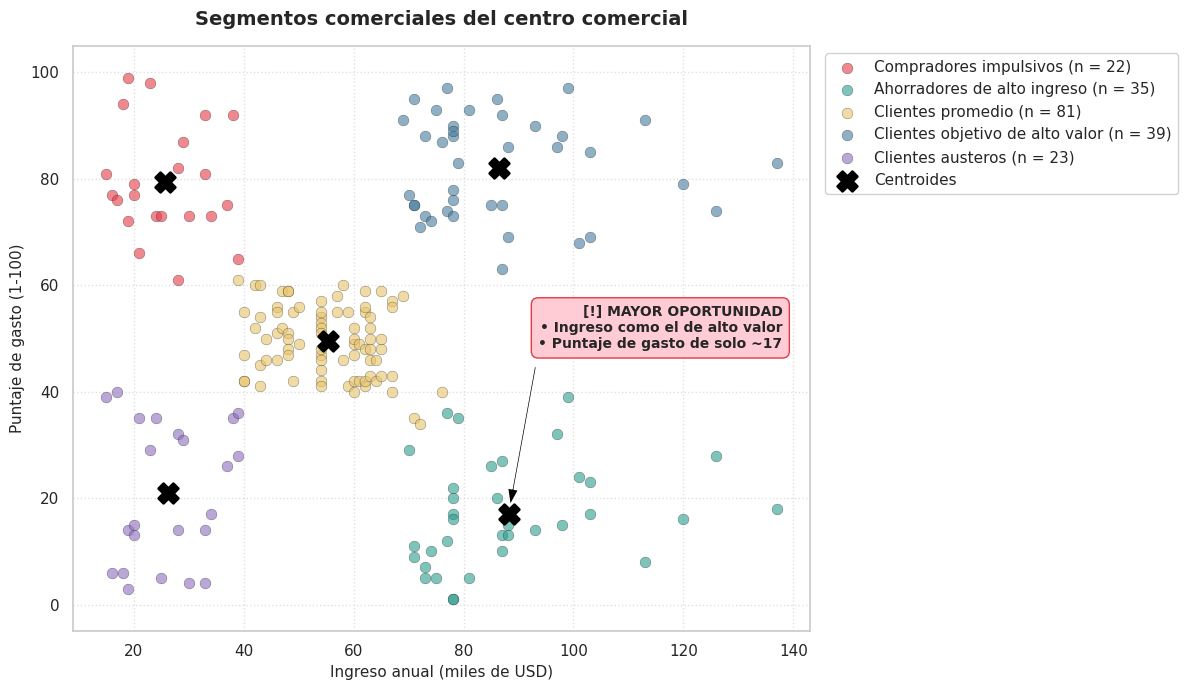

In [25]:
# ==============================================================================
# VISUALIZACIÓN FINAL DE LOS SEGMENTOS COMERCIALES
# ==============================================================================

fig, ax = plt.subplots(figsize=(12, 7))

for cluster_id in range(K_OPTIMO):
    puntos = mall_prep_df[mall_prep_df["Cluster_KM"] == cluster_id]
    ax.scatter(puntos["Ingreso_Anual_kUSD"], puntos["Puntaje_Gasto"], color=colores[cluster_id],
               alpha=0.6, edgecolor="k", linewidth=0.3, s=60,
               label=f"{nombres_segmento[cluster_id]} (n = {len(puntos)})")

ax.scatter(centroides_originales[:, 0], centroides_originales[:, 1], color="black", marker="X",
           s=200, linewidths=2, zorder=10, label="Centroides")

# Resaltar el segmento con mayor oportunidad: ingreso alto y gasto bajo
cluster_oportunidad = [c for c, n in nombres_segmento.items() if n == "Ahorradores de alto ingreso"][0]
ax.annotate("[!] MAYOR OPORTUNIDAD\n• Ingreso como el de alto valor\n• Puntaje de gasto de solo ~17",
            xy=(centroides_originales[cluster_oportunidad, 0], centroides_originales[cluster_oportunidad, 1]),
            xytext=(138, 52), ha="right", va="center",
            arrowprops=dict(facecolor="black", shrink=0.05, width=1.5, headwidth=8),
            fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", facecolor="#FFCCD5", edgecolor="#E63946"))

ax.set_title("Segmentos comerciales del centro comercial", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Ingreso anual (miles de USD)", fontsize=11)
ax.set_ylabel("Puntaje de gasto (1-100)", fontsize=11)
ax.set_ylim(-5, 105)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True, facecolor="white", framealpha=0.9)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

#### Informe ejecutivo de cierre para la gerencia

Realicé un análisis de 200 clientes a partir de su ingreso anual y su puntaje de gasto, y encontré cinco segmentos confirmados con K-Means y con clustering jerárquico, que coinciden en 196 de los 200 clientes (ARI de 0,94). El grupo más grande es el de los clientes promedio (40,5 %), con ingresos de 55 mil dólares y un puntaje de 50: una base estable, aunque sin la mayor oportunidad. Los clientes de alto valor (19,5 %), de 33 años, con ingresos de 87 mil dólares y un puntaje de 82, ya gastan de acuerdo con su capacidad, mientras que los compradores impulsivos (11 %), de 25 años, con ingresos de 26 mil dólares y un puntaje de 79, gastan más de lo que su ingreso podría sugerir. En el otro extremo están los clientes austeros (11,5 %), con ingresos de 26 mil dólares y un puntaje de 21, y los ahorradores de alto ingreso.

La oportunidad más clara está en los ahorradores: son 35 clientes (17,5 %) con ingresos de 88 mil dólares, similares a los de los clientes de alto valor, pero con un puntaje de gasto de 17 frente a 82. Tienen capacidad para gastar, pero no lo hacen en el centro comercial, por lo que recomiendo motivarlos a consumir, en lugar de ofrecerles descuentos, con eventos, lanzamientos de marcas de gama media y alta, experiencias gastronómicas y de servicios, y comunicación personalizada. Es posible que gasten en otro lugar o que no conozcan la oferta, pero esta es una hipótesis que debe validarse.

Para los clientes de alto valor, la prioridad es mantener su fidelidad con preventas, atención preferencial y acumulación de puntos. Los compradores impulsivos podrían responder a incentivos de corto plazo, como promociones, cupones y campañas en redes sociales, teniendo en cuenta que sus ingresos son bajos. Para los clientes promedio y austeros propongo una comunicación masiva de bajo costo y beneficios básicos de puntos, sin descuentos fuertes, y buscar que algunos clientes promedio aumenten su gasto. Como limitación, el puntaje de gasto lo asigna el propio centro comercial y el análisis considera solo 200 clientes y dos variables; por eso, antes de realizar una inversión importante, recomiendo hacer un piloto pequeño para cada segmento.

### **Resumen de la Parte 2**

El dendrograma de Ward es el único con un corte claro y lo corté en cinco grupos. El ARI contra K-Means es 0.942 y solo cuatro clientes de frontera cambian de grupo. Armé los perfiles en escala original y cinco segmentos comerciales, con una estrategia para cada uno y el mayor potencial en los ahorradores de alto ingreso.

## Declaración de uso de IA generativa

**Herramientas:** Claude (modelo Claude Sonnet 5.5, de Anthropic), usado mediante Claude Code, y GPT (versión «lunar medio»), usado solo para mejorar mis prompts. **Período de uso:** noviembre de 2026.

### Para qué las usé
Usé las herramientas con cinco propósitos:

1. **Adaptación del código**. Para entender los parámetros y las configuraciones de los notebooks de ejemplo del docente, y para resolver los errores que surgieron al personalizar ese código para esta actividad. Esa comprensión fue fundamental para saber qué variables de configuración debía modificar y por qué.
2. **Redacción.** Para mejorar la ortografía, la puntuación, la claridad y la cohesión de mis textos explicativos (celdas de Markdown).
3. **Comprensión y depuración.** Para entender conceptos que aplico en el cuaderno (K-Means, método del codo, silueta, escalamiento, clustering jerárquico, atípicos) y para diagnosticar errores de ejecución.
4. **Revisión.** Para contrastar mis interpretaciones con los resultados reales del cuaderno y para recibir una revisión crítica de la entrega frente a la guía de la actividad.
5. **Mejora de prompts.** Para mejorar la redacción de los prompts que luego envié a Claude y así obtener respuestas más precisas.

### Qué hizo la herramienta y qué hice yo
- **Código:** la mayor parte del código la tomé de los notebooks de ejemplo de clase y la adapté a Mall Customers (variables, parámetros, gráficos y análisis). Claude me ayudó a entender qué debía configurar y entender la personalizacion que no entendia y a depurar errores. En la sesión de apoyo, Claude leyó el cuaderno y sus salidas, pero no lo modificó.
- **Redacción:** Claude corrigió errores ortográficos y de puntuación, reordenó oraciones, agregó conectores y ajustó el registro de textos que yo había escrito. A petición mía, ayudó a ampliar la explicación del efecto de no escalar los datos y a condensar el informe final a tres párrafos.
- **Explicaciones y revisión:** Claude me explicó conceptos, sugirió fragmentos de código de diagnóstico y verificación, y señaló inconsistencias entre mis textos y las salidas del cuaderno.
- **Decisiones:** las decisiones de análisis (variables, estandarización, tratamiento de los atípicos, *k* = 5, criterio de enlace, punto de corte, nombres de segmentos y estrategias) son mías y se justifican con los resultados del cuaderno. Todas las cifras provienen de las salidas de mi cuaderno, y las que la herramienta señaló para verificar las contrasté antes de conservarlas.

### Prompts utilizados (resumidos) y propósito
Los prompts se muestran resumidos. Para obtener respuestas más precisas, mejoré su redacción con apoyo de GPT antes de enviarlos a Claude.

**Redacción**
- «Mejora la redacción, ortografía, puntuación y coherencia de este texto para incluirlo en un informe, conservando las ideas, los datos y las recomendaciones.»
- «Ayúdame a explicar mejor qué pasaría si no escalo los datos.»
- «El informe está muy largo: debe tener como máximo tres párrafos y como mínimo dos.»

**Comprensión de conceptos**
- Parámetros de K-Means: «¿Qué controlan `n_clusters`, `random_state` y `n_init`, y qué resultado usa el modelo entre las varias inicializaciones?» y «¿Qué diferencia hay entre `fit`, `predict` y `fit_predict`?»
- Método del codo: «¿Qué calcula `inertia_` y por qué baja al aumentar *k*?» y «¿Cómo interpreto el ciclo del codo y qué significa que la curva se aplane?»
- Clustering jerárquico: «¿Qué representa la matriz `Z` de `linkage`?», «Explica con un ejemplo Ward, completo y promedio», y «¿Qué índices de `Z` uso para la altura de corte de cinco grupos?»
- Silueta: «¿Qué significa un coeficiente de 0,5547 y qué no puedo concluir con esa métrica?»
- Escalamiento: «¿Cómo influyen las unidades en las distancias y qué muestra mi experimento con y sin escalar?»
- Atípicos: «¿Qué significa que sean atípicos según el IQR y por qué puedo conservarlos si no parecen errores?»
- Comparación de algoritmos: «¿Por qué algunos clientes cambian de grupo entre K-Means y Ward?»

**Depuración de errores**
- `KeyError: ['Puntaje_Gasto'] not in index` al seleccionar las variables.
- `ValueError: Input X contains NaN` al ajustar K-Means.
- Filas que desaparecen o quedan vacías al combinar perfiles y estrategias.
- Error en el índice de la paleta de colores de la gráfica final.

**Revisión y verificación**
- «Interpreta el gráfico del codo con mis valores reales: ¿por qué elegí cinco grupos y qué tan clara es la decisión? No afirmes que el codo es evidente si los resultados no lo muestran.»
- «Revisa si mis recomendaciones comerciales corresponden a los perfiles que encontré.»
- «Revisa mi entrega frente a la guía, compórtate como evaluador e indica qué fallas tiene y qué le falta.»

### Revisión y responsabilidad
Revisé cada texto y cada fragmento de código propuesto antes de incorporarlo. Cuando la herramienta sugirió frases nuevas o señaló cifras por verificar, las contrasté con las salidas del cuaderno antes de decidir si las conservaba. Asumo la responsabilidad por el contenido final de este trabajo.
